In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("Tools loaded!")
print("Files in this folder:", os.listdir("."))

Tools loaded!
Files in this folder: ['batteries.csv', 'city_daily_context.csv', 'clean', 'fleet_partners.csv', 'one_cleaning.ipynb', 'riders.csv', 'stations.csv', 'station_hourly_status.csv', 'support_tickets.csv', 'swap_events.csv']


In [32]:
stations   = pd.read_csv("stations.csv")
riders     = pd.read_csv("riders.csv")
batteries  = pd.read_csv("batteries.csv")
tickets    = pd.read_csv("support_tickets.csv")
city_ctx   = pd.read_csv("city_daily_context.csv")
partners   = pd.read_csv("fleet_partners.csv")

print("stations:", stations.shape)
print("riders:", riders.shape)
print("batteries:", batteries.shape)
print("tickets:", tickets.shape)
print("city_ctx:", city_ctx.shape)
print("partners:", partners.shape)

stations: (152, 22)
riders: (20000, 12)
batteries: (6500, 13)
tickets: (44000, 12)
city_ctx: (3282, 12)
partners: (12, 12)


In [33]:
stations.head()

,station_id,city,zone,latitude,longitude,location_type,host_type,commissioned_date,decommissioned_date,expansion_wave,...,slots_3w,inventory_target_2w,inventory_target_3w,monthly_rent_inr,monthly_maintenance_inr,grid_tariff_inr_kwh,connectivity_tier,firmware_version,firmware_updated_date,competitor_within_1_5km_since
0,STN-BLR-001,Bengaluru,BLR-Electronic City,12.926943,77.604655,transit_hub,mall_parking,2023-12-09,NaN,Launch,...,6,32,7,23247,5436,9.29,good,v3.2.1,2025-04-14,NaN
1,STN-BLR-002,Bengaluru,BLR-Central,13.149199,77.530565,commercial_hub,kirana,2023-06-20,NaN,Launch,...,0,38,0,23201,5249,8.41,poor,v3.2.1,2025-04-14,NaN
2,STN-BLR-003,Bengaluru,BLR-Electronic City,12.917986,77.607560,commercial_hub,fuel_retailer,2023-09-26,NaN,Launch,...,0,43,0,10281,4516,8.66,good,v3.2.1,2025-04-14,NaN
3,STN-BLR-004,Bengaluru,BLR-Whitefield,13.030901,77.489397,market,mall_parking,2023-08-25,NaN,Launch,...,0,33,0,12322,5802,9.19,good,v3.2.1,2025-04-14,NaN
4,STN-BLR-005,Bengaluru,BLR-North,12.815864,77.628712,residential,mall_parking,2023-11-07,NaN,Launch,...,0,15,0,24194,7134,8.68,fair,v3.2.1,2025-04-14,NaN


In [34]:
test_stations = stations[stations["station_id"].str.startswith("STN-TST")]
print("Number of test stations:", len(test_stations))
test_stations[["station_id", "city", "location_type"]]

Number of test stations: 2


,station_id,city,location_type
150,STN-TST-01,Bengaluru,commercial_hub
151,STN-TST-02,Bengaluru,commercial_hub


In [35]:
stations = stations[~stations["station_id"].str.startswith("STN-TST")]
print("Stations left:", len(stations))

Stations left: 150


In [36]:
riders["home_city"].value_counts(dropna=False)

home_city
Bengaluru     4175
Delhi NCR     3783
Hyderabad     3396
Pune          2843
Mumbai        2772
Jaipur        2446
Bombay          53
BLR             53
bengaluru       50
MUM             49
PUN             43
pune            43
New Delhi       42
JAI             41
Gurgaon         36
Bangalore       32
HYD             31
Hyd             31
jaipur          29
hyderabad       27
Delhi           25
Name: count, dtype: int64

In [37]:
city_fix = {
    "bengaluru": "Bengaluru", "bangalore": "Bengaluru", "blr": "Bengaluru",
    "delhi ncr": "Delhi NCR", "new delhi": "Delhi NCR", "delhi": "Delhi NCR", "gurgaon": "Delhi NCR",
    "hyderabad": "Hyderabad", "hyd": "Hyderabad",
    "pune": "Pune", "pun": "Pune",
    "mumbai": "Mumbai", "bombay": "Mumbai", "mum": "Mumbai",
    "jaipur": "Jaipur", "jai": "Jaipur",
}

riders["city_clean"] = riders["home_city"].str.strip().str.lower().map(city_fix)

print("Cities that did not match:", riders["city_clean"].isna().sum())
riders["city_clean"].value_counts()

Cities that did not match: 0


city_clean
Bengaluru    4310
Delhi NCR    3886
Hyderabad    3485
Pune         2929
Mumbai       2874
Jaipur       2516
Name: count, dtype: int64

In [38]:
category_cols = ["rider_id", "station_id", "event_type", "battery_in_id", "battery_out_id",
                 "tariff_code", "payment_mode", "station_firmware", "sync_mode"]

swaps = pd.read_csv(
    "swap_events.csv.gz",
    parse_dates=["event_ts"],
    dtype={c: "category" for c in category_cols},
)

print("Size (rows, columns):", swaps.shape)
swaps.head()

FileNotFoundError: [Errno 2] No such file or directory: 'swap_events.csv.gz'

In [ ]:
import os
for f in sorted(os.listdir(".")):
    print(f)

batteries.csv
city_daily_context.csv
fleet_partners.csv
one_cleaning.ipynb
riders.csv
station_hourly_status.csv
stations.csv
support_tickets.csv
swap_events.csv


In [ ]:
category_cols = ["rider_id", "station_id", "event_type", "battery_in_id", "battery_out_id",
                 "tariff_code", "payment_mode", "station_firmware", "sync_mode"]

swaps = pd.read_csv(
    "swap_events.csv",
    parse_dates=["event_ts"],
    dtype={c: "category" for c in category_cols},
)

print("Size (rows, columns):", swaps.shape)
swaps.head()

Size (rows, columns): (3877013, 22)


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,...,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88,BAT-2W-103542,BAT-2W-102547,15.0,...,98.9,80.4,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148,BAT-2W-105296,BAT-2W-101923,8.3,...,98.2,66.1,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307,BAT-2W-104732,BAT-2W-102492,11.5,...,99.1,66.6,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime
3,SW-000000004,RD-1000006,STN-JAI-135,2024-01-01 20:26:07,swap_completed,1,399,BAT-2W-103839,BAT-2W-103267,7.9,...,98.2,65.4,STD,60.0,0.0,60.0,partner_invoice,2.194,v3.2.0,realtime
4,SW-000000005,RD-1000012,STN-PUN-100,2024-01-01 21:13:07,swap_completed,1,201,BAT-2W-104056,BAT-2W-106218,10.5,...,99.9,73.8,STD,60.0,0.0,60.0,partner_invoice,1.971,v3.2.1,realtime


In [ ]:
print("First event:", swaps["event_ts"].min())
print("Last event: ", swaps["event_ts"].max())

First event: 2024-01-01 00:00:33
Last event:  2025-06-30 23:59:23


In [ ]:
counts = swaps["event_type"].value_counts()
percent = (swaps["event_type"].value_counts(normalize=True) * 100).round(2)

pd.DataFrame({"number of attempts": counts, "percent": percent})

,number of attempts,percent
event_type,,
swap_completed,3645809,94.04
failed_no_charged_battery,134389,3.47
abandoned_queue,68533,1.77
cancelled_by_rider,16712,0.43
failed_system_error,11570,0.30


In [ ]:
is_test = swaps["station_id"].astype(str).str.startswith("STN-TST")

print("Swap rows at test stations:", is_test.sum())
print("Stations left in station list:", len(stations))

swaps = swaps[~is_test].copy()
print("Swap rows after removal:", len(swaps))

Swap rows at test stations: 62031
Stations left in station list: 150
Swap rows after removal: 3814982


In [ ]:
fw = swaps["station_firmware"].astype(str)
print(fw.value_counts())

bug = (fw == "v3.2.0") & (swaps["event_ts"] >= "2025-03-10") & (swaps["event_ts"] < "2025-04-15")
print()
print("Possibly affected rows:", bug.sum())

station_firmware
v3.2.1    2253808
v3.2.0    1561174
Name: count, dtype: int64

Possibly affected rows: 139490


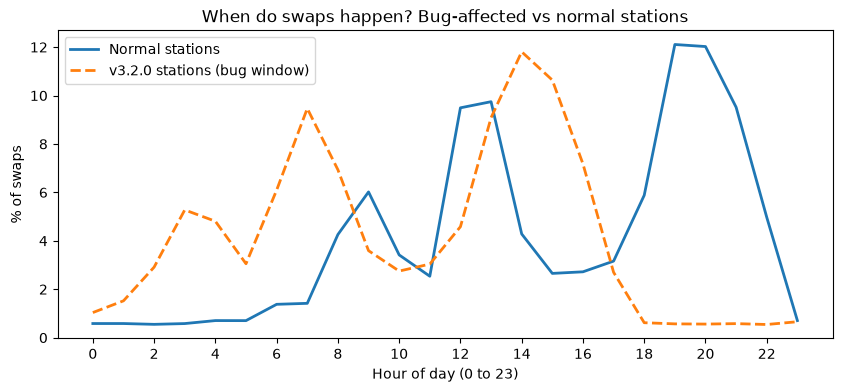

In [ ]:
window = (swaps["event_ts"] >= "2025-03-10") & (swaps["event_ts"] < "2025-04-15")

hours_bug = swaps.loc[bug, "event_ts"].dt.hour.value_counts(normalize=True).sort_index()
hours_ok  = swaps.loc[window & ~bug, "event_ts"].dt.hour.value_counts(normalize=True).sort_index()

plt.figure(figsize=(10, 4))
plt.plot(hours_ok.index, hours_ok.values * 100, label="Normal stations", linewidth=2)
plt.plot(hours_bug.index, hours_bug.values * 100, label="v3.2.0 stations (bug window)", linewidth=2, linestyle="--")
plt.xlabel("Hour of day (0 to 23)")
plt.ylabel("% of swaps")
plt.title("When do swaps happen? Bug-affected vs normal stations")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.show()

In [ ]:
if "ts_was_fixed" not in swaps.columns:
    swaps["ts_was_fixed"] = bug
    swaps.loc[bug, "event_ts"] = swaps.loc[bug, "event_ts"] + pd.Timedelta(hours=5, minutes=30)
    print("Fixed rows:", swaps["ts_was_fixed"].sum())
else:
    print("Already fixed, nothing changed.")

Fixed rows: 139490


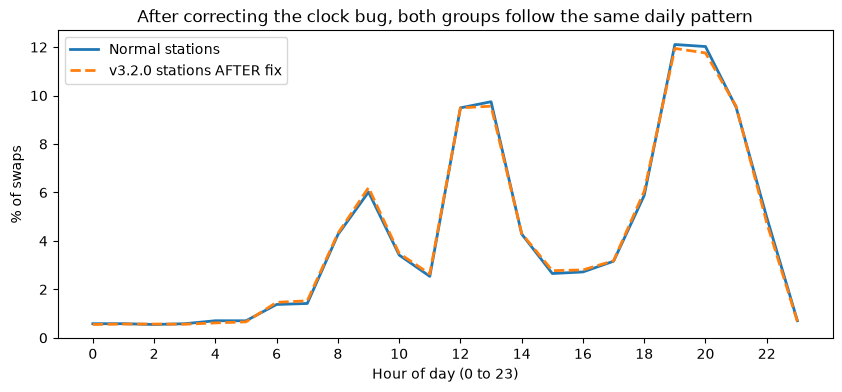

In [ ]:
window = (swaps["event_ts"] >= "2025-03-10") & (swaps["event_ts"] < "2025-04-15")

hours_fixed  = swaps.loc[swaps["ts_was_fixed"], "event_ts"].dt.hour.value_counts(normalize=True).sort_index()
hours_normal = swaps.loc[window & ~swaps["ts_was_fixed"], "event_ts"].dt.hour.value_counts(normalize=True).sort_index()

plt.figure(figsize=(10, 4))
plt.plot(hours_normal.index, hours_normal.values * 100, label="Normal stations", linewidth=2)
plt.plot(hours_fixed.index, hours_fixed.values * 100, label="v3.2.0 stations AFTER fix", linewidth=2, linestyle="--")
plt.xlabel("Hour of day (0 to 23)")
plt.ylabel("% of swaps")
plt.title("After correcting the clock bug, both groups follow the same daily pattern")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.show()

In [ ]:
keys = ["rider_id", "station_id", "event_type", "battery_in_id", "battery_out_id"]

check = swaps[keys + ["event_ts", "sync_mode"]].copy()
for c in keys:
    check[c] = check[c].astype(str)

check = check.sort_values(keys + ["event_ts"])

gap = check.groupby(keys, sort=False)["event_ts"].diff().dt.total_seconds()
is_offline = check["sync_mode"].astype(str) == "offline_batch"

print("Rows sent in offline batch mode:", is_offline.sum())
print()
for seconds in [60, 120, 180, 300]:
    print(f"Likely duplicates if within {seconds} seconds:", (is_offline & (gap <= seconds)).sum())

Rows sent in offline batch mode: 591114

Likely duplicates if within 60 seconds: 0
Likely duplicates if within 120 seconds: 0
Likely duplicates if within 180 seconds: 0
Likely duplicates if within 300 seconds: 0


In [ ]:
loose_keys = ["rider_id", "station_id", "battery_in_id"]

check2 = swaps[loose_keys + ["event_ts", "sync_mode", "event_type"]].copy()
for c in loose_keys + ["sync_mode", "event_type"]:
    check2[c] = check2[c].astype(str)

# ignore rows where the rider never inserted a battery (nothing to match on)
check2 = check2[check2["battery_in_id"] != "nan"]
check2 = check2.sort_values(loose_keys + ["event_ts"])

grp = check2.groupby(loose_keys, sort=False)
gap2 = grp["event_ts"].diff().dt.total_seconds()
prev_sync = grp["sync_mode"].shift()
prev_type = grp["event_type"].shift()

close = gap2 <= 300
print("Pairs of rows within 300 seconds (any sync mode):", close.sum())
print("  ...where at least one row is offline_batch:", (close & ((check2["sync_mode"] == "offline_batch") | (prev_sync == "offline_batch"))).sum())
print("  ...where BOTH rows are offline_batch:", (close & (check2["sync_mode"] == "offline_batch") & (prev_sync == "offline_batch")).sum())
print("  ...where the outcome is the same in both rows:", (close & (check2["event_type"] == prev_type)).sum())

Pairs of rows within 300 seconds (any sync mode): 3
  ...where at least one row is offline_batch: 0
  ...where BOTH rows are offline_batch: 0
  ...where the outcome is the same in both rows: 3


In [ ]:
k = ["rider_id", "station_id"]

c3 = swaps[k + ["event_ts", "sync_mode", "event_type"]].copy()
for c in k + ["sync_mode", "event_type"]:
    c3[c] = c3[c].astype(str)

c3 = c3.sort_values(k + ["event_ts"])
g = c3.groupby(k, sort=False)

gap3 = g["event_ts"].diff().dt.total_seconds()
prev_sync = g["sync_mode"].shift()
either_offline = (c3["sync_mode"] == "offline_batch") | (prev_sync == "offline_batch")

for s in [120, 300]:
    close = gap3 <= s
    print(f"Within {s} seconds: {close.sum()} pairs, of which {(close & either_offline).sum()} involve an offline_batch row")

Within 120 seconds: 4246 pairs, of which 1017 involve an offline_batch row
Within 300 seconds: 10673 pairs, of which 2504 involve an offline_batch row


In [ ]:
print("Distance (km) summary:")
print(swaps["km_since_last_swap"].describe(percentiles=[0.01, 0.5, 0.99, 0.999]).round(1))

print()
print("Negative distances:", (swaps["km_since_last_swap"] < 0).sum())
print("Distances over 300 km:", (swaps["km_since_last_swap"] > 300).sum())

print()
for col in ["soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct"]:
    print(col, "above 100:", (swaps[col] > 100).sum())
    

Distance (km) summary:
count    3787124.0
mean          62.0
std           20.5
min          -20.0
1%            32.5
50%           59.9
99%          107.0
99.9%        371.0
max          420.0
Name: km_since_last_swap, dtype: float64

Negative distances: 7687
Distances over 300 km: 7600

soc_in_pct above 100: 0
soh_in_pct above 100: 3298
soc_out_pct above 100: 3634
soh_out_pct above 100: 2752


In [ ]:
km = swaps["km_since_last_swap"]

print("Rows between 0 and 150 km (normal):", ((km >= 0) & (km <= 150)).sum())
print("Rows between 150 and 200 km:", ((km > 150) & (km <= 200)).sum())
print("Rows between 200 and 300 km:", ((km > 200) & (km <= 300)).sum())
print("Rows over 300 km:", (km > 300).sum())
print()

swaps["km_invalid"] = (km < 0) | (km > 200)
swaps["km_clean"] = km.where(~swaps["km_invalid"])

for col in ["soh_in_pct", "soc_out_pct", "soh_out_pct"]:
    swaps[col] = swaps[col].clip(upper=100)

print("Distances marked as errors:", swaps["km_invalid"].sum())
print("Largest valid distance now:", swaps["km_clean"].max())
print("Highest charge/health reading now:", swaps[["soh_in_pct", "soc_out_pct", "soh_out_pct"]].max().max())

Rows between 0 and 150 km (normal): 3771837
Rows between 150 and 200 km: 0
Rows between 200 and 300 km: 0
Rows over 300 km: 7600

Distances marked as errors: 15287
Largest valid distance now: 136.7
Highest charge/health reading now: 100.0


In [ ]:
hourly = pd.read_csv("station_hourly_status.csv", parse_dates=["hour_start"])
print("Size (rows, columns):", hourly.shape)

hourly = hourly[~hourly["station_id"].str.startswith("STN-TST")].copy()
print("After removing test stations:", hourly.shape)

print()
print((hourly["telemetry_status"].value_counts(normalize=True) * 100).round(1))

Size (rows, columns): (1487712, 14)
After removing test stations: (1461456, 14)

telemetry_status
ok         96.8
partial     2.5
missing     0.6
Name: proportion, dtype: float64


In [ ]:
hourly = hourly.merge(stations[["station_id", "connectivity_tier"]], on="station_id", how="left")

table = pd.crosstab(hourly["connectivity_tier"], hourly["telemetry_status"], normalize="index") * 100
table.round(1)

telemetry_status,missing,ok,partial
connectivity_tier,,,
fair,0.0,96.1,3.9
good,0.0,99.0,1.0
poor,4.0,89.1,6.9


In [ ]:
hourly["telemetry_ok"] = hourly["telemetry_status"] == "ok"

tickets = tickets[~tickets["station_id"].astype(str).str.startswith("STN-TST")].copy()

print("hourly rows we can fully trust:", hourly["telemetry_ok"].sum(), "of", len(hourly))
print("tickets after removing test stations:", len(tickets))

hourly rows we can fully trust: 1415325 of 1461456
tickets after removing test stations: 43465


In [ ]:
os.makedirs("clean", exist_ok=True)

swaps.to_pickle("clean/swaps_clean.pkl")
hourly.to_pickle("clean/hourly_clean.pkl")
riders.to_pickle("clean/riders_clean.pkl")
stations.to_pickle("clean/stations_clean.pkl")
batteries.to_pickle("clean/batteries.pkl")
tickets.to_pickle("clean/tickets_clean.pkl")
city_ctx.to_pickle("clean/city_ctx.pkl")
partners.to_pickle("clean/partners.pkl")

print("Saved:", os.listdir("clean"))

Saved: ['batteries.pkl', 'city_ctx.pkl', 'hourly_clean.pkl', 'partners.pkl', 'riders_clean.pkl', 'stations_clean.pkl', 'swaps_clean.pkl', 'tickets_clean.pkl']


In [ ]:
print("Repeated event_ids in swaps:", swaps["event_id"].duplicated().sum())
print("Repeated rider_ids in riders:", riders["rider_id"].duplicated().sum())
print("Repeated station_ids in stations:", stations["station_id"].duplicated().sum())
print("Repeated battery_ids in batteries:", batteries["battery_id"].duplicated().sum())

print()
print("Swaps whose rider is not in riders:", (~swaps["rider_id"].astype(str).isin(riders["rider_id"])).sum())
print("Swaps whose station is not in stations:", (~swaps["station_id"].astype(str).isin(stations["station_id"])).sum())

battery_ids = set(batteries["battery_id"])
for col in ["battery_in_id", "battery_out_id"]:
    ids = swaps[col].dropna().astype(str)
    print(col, "not found in batteries:", (~ids.isin(battery_ids)).sum())

print()
print("Negative wait times:", (swaps["queue_wait_sec"] < 0).sum())
print("Negative amounts charged:", (swaps["amount_charged_inr"] < 0).sum())

Repeated event_ids in swaps: 0
Repeated rider_ids in riders: 0
Repeated station_ids in stations: 0
Repeated battery_ids in batteries: 0

Swaps whose rider is not in riders: 0
Swaps whose station is not in stations: 0
battery_in_id not found in batteries: 0
battery_out_id not found in batteries: 0

Negative wait times: 0
Negative amounts charged: 0


In [ ]:
def attach(df, key, lookup, cols, rename=None):
    """Copy columns from a small lookup table onto every row of df, matching on the key column."""
    cats = df[key].cat.categories
    codes = df[key].cat.codes.values
    lk = lookup.set_index(key)[cols].reindex(cats.astype(str))
    for c in cols:
        new_name = (rename or {}).get(c, c)
        values = lk[c].values[codes]
        df[new_name] = values

# station details
attach(swaps, "station_id", stations,
       ["city", "zone", "location_type", "host_type", "expansion_wave",
        "charger_generation", "connectivity_tier", "commissioned_date", "grid_tariff_inr_kwh"])

# rider details (rider's home city is renamed so it can't be confused with the station's city)
attach(swaps, "rider_id", riders,
       ["vehicle_class", "partner_id", "plan_type", "signup_channel", "signup_date", "city_clean"],
       rename={"city_clean": "rider_city"})

swaps["partner_id"] = swaps["partner_id"].fillna("Independent")

for c in ["city", "zone", "location_type", "host_type", "expansion_wave", "charger_generation",
          "connectivity_tier", "vehicle_class", "partner_id", "plan_type", "signup_channel", "rider_city"]:
    swaps[c] = swaps[c].astype("category")

print("Done. New size:", swaps.shape)

Done. New size: (3814982, 40)


In [ ]:
new_cols = ["city", "zone", "location_type", "charger_generation", "connectivity_tier",
            "vehicle_class", "partner_id", "plan_type", "rider_city"]
print("Blank values after joining (should all be 0):")
print(swaps[new_cols].isna().sum())

print()
print("Swap attempts by station city:")
print(swaps["city"].value_counts())

Blank values after joining (should all be 0):
city                  0
zone                  0
location_type         0
charger_generation    0
connectivity_tier     0
vehicle_class         0
partner_id            0
plan_type             0
rider_city            0
dtype: int64

Swap attempts by station city:
city
Delhi NCR    768913
Bengaluru    763296
Hyderabad    711930
Pune         552910
Mumbai       530299
Jaipur       487634
Name: count, dtype: int64


In [ ]:
swaps.to_pickle("clean/swaps_clean.pkl")
print("Saved.")

Saved.


In [41]:
swaps["month"] = swaps["event_ts"].dt.to_period("M").astype(str)
swaps["completed"] = swaps["event_type"] == "swap_completed"
swaps["service_failure"] = swaps["event_type"].isin(
    ["failed_no_charged_battery", "abandoned_queue", "failed_system_error"]
)
print("Service failures overall:", round(swaps["service_failure"].mean() * 100, 2), "%")

Service failures overall: 5.55 %


In [42]:
monthly = swaps.groupby("month").agg(
    attempts=("event_id", "size"),
    completed_swaps=("completed", "sum"),
    failure_rate_pct=("service_failure", "mean"),
)
monthly["failure_rate_pct"] = (monthly["failure_rate_pct"] * 100).round(2)
monthly

,attempts,completed_swaps,failure_rate_pct
month,,,
2024-01,108278,103508,4.00
2024-02,109271,104437,4.01
2024-03,121487,116148,3.95
2024-04,128991,120117,6.48
2024-05,143189,125454,11.93
2024-06,145880,130880,9.85
2024-07,155343,148611,3.92
2024-08,168900,161688,3.83
2024-09,192479,184051,3.95


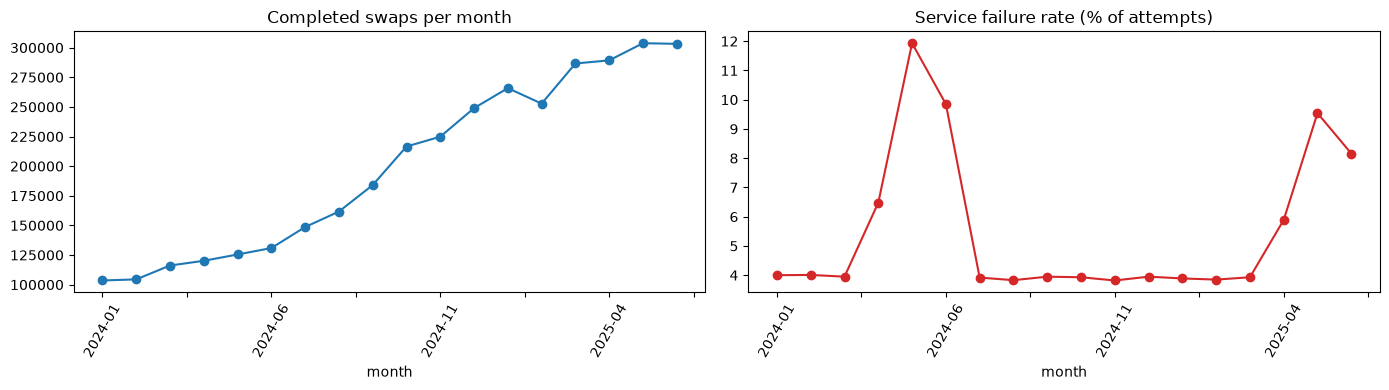

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

monthly["completed_swaps"].plot(ax=ax[0], marker="o")
ax[0].set_title("Completed swaps per month")
ax[0].tick_params(axis="x", rotation=60)

monthly["failure_rate_pct"].plot(ax=ax[1], marker="o", color="tab:red")
ax[1].set_title("Service failure rate (% of attempts)")
ax[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [44]:
fail_types = ["failed_no_charged_battery", "abandoned_queue", "failed_system_error"]
by_type = pd.crosstab(swaps["month"], swaps["event_type"], normalize="index") * 100
by_type[fail_types].round(2)

event_type,failed_no_charged_battery,abandoned_queue,failed_system_error
month,,,
2024-01,2.44,1.27,0.29
2024-02,2.40,1.30,0.31
2024-03,2.37,1.27,0.31
2024-04,4.13,2.05,0.30
2024-05,7.82,3.81,0.31
2024-06,6.43,3.12,0.31
2024-07,2.35,1.28,0.29
2024-08,2.29,1.26,0.27
2024-09,2.39,1.25,0.32


charger_generation   Gen1  Gen2  Gen3
month                                
2024-01              3.92  4.09   NaN
2024-02              3.91  4.14   NaN
2024-03              3.90  4.01   NaN
2024-04              8.02  4.36   NaN
2024-05             16.06  6.31   NaN
2024-06             13.41  4.99   NaN
2024-07              3.95  3.89   NaN
2024-08              3.91  3.71  3.88
2024-09              3.95  3.95  4.20
2024-10              3.90  3.96  4.05
2024-11              3.76  3.89  3.72
2024-12              3.99  3.92  3.82
2025-01              3.84  3.96  3.65
2025-02              3.86  3.87  3.71
2025-03              3.86  3.98  3.99
2025-04              8.03  4.63  4.28
2025-05             15.73  6.29  4.98
2025-06             13.27  5.35  4.74


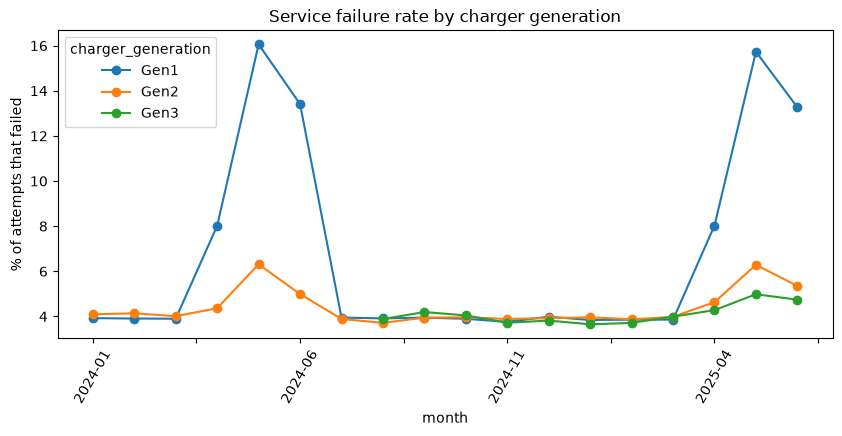

In [45]:
gen = swaps.groupby(["month", "charger_generation"], observed=True)["service_failure"].mean().unstack() * 100
print(gen.round(2))

gen.plot(marker="o", figsize=(10, 4))
plt.title("Service failure rate by charger generation")
plt.ylabel("% of attempts that failed")
plt.xticks(rotation=60)
plt.show()

city     Bengaluru  Delhi NCR  Hyderabad  Jaipur  Mumbai  Pune
month                                                         
2024-01       3.97       3.92       4.07    3.83    4.19  3.98
2024-02       4.31       3.95       3.89    3.77    3.99  4.01
2024-03       4.02       3.85       3.73    3.84    4.11  4.16
2024-04       3.86       9.69       5.32   13.03    4.08  4.05
2024-05       5.92      16.49      17.24   19.38    4.11  9.37
2024-06       4.11      15.51      13.63   18.45    3.93  4.28
2024-07       3.76       4.07       3.84    3.96    3.96  4.02
2024-08       3.72       3.88       3.90    3.90    3.74  3.85
2024-09       3.93       4.03       4.01    3.66    3.93  4.07
2024-10       3.94       3.91       3.74    3.97    3.95  4.17
2024-11       3.81       3.77       3.73    3.80    3.94  3.93
2024-12       3.98       3.87       3.79    4.07    4.15  3.91
2025-01       3.95       3.82       3.97    3.68    4.04  3.84
2025-02       3.83       3.80       3.79    3.81    3.9

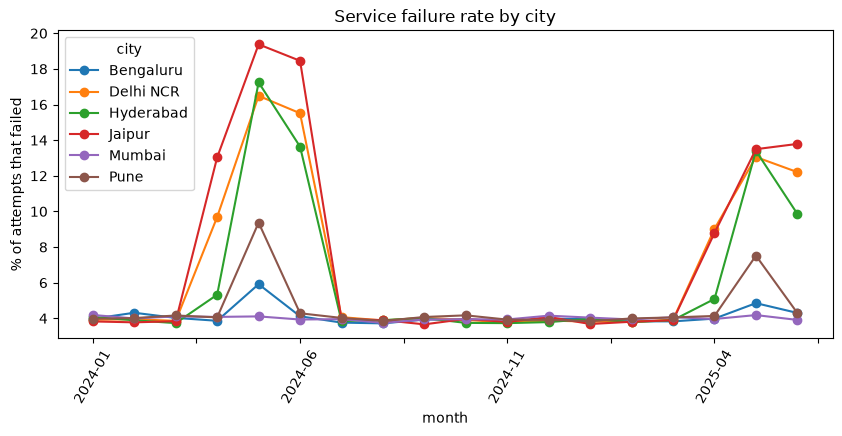

In [46]:
city = swaps.groupby(["month", "city"], observed=True)["service_failure"].mean().unstack() * 100
print(city.round(2))

city.plot(marker="o", figsize=(10, 4))
plt.title("Service failure rate by city")
plt.ylabel("% of attempts that failed")
plt.xticks(rotation=60)
plt.show()

In [47]:
pd.crosstab(stations["city"], stations["charger_generation"])

charger_generation,Gen1,Gen2,Gen3
city,,,
Bengaluru,9,16,7
Delhi NCR,13,10,7
Hyderabad,13,6,7
Jaipur,10,3,5
Mumbai,2,15,5
Pune,4,12,6


In [48]:
hot = swaps[swaps["month"].isin(["2024-05", "2025-05"])]

rates = hot.groupby(["city", "charger_generation"], observed=True)["service_failure"].mean().unstack() * 100
counts = hot.groupby(["city", "charger_generation"], observed=True).size().unstack()

print("Failure rate (%) in May 2024 and May 2025 combined:")
print(rates.round(1))
print()
print("Number of attempts behind each number:")
print(counts)

Failure rate (%) in May 2024 and May 2025 combined:
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru            6.2   4.7   4.1
Delhi NCR           19.2   9.4   5.8
Hyderabad           19.0   9.4   5.1
Jaipur              18.9   9.8   5.5
Mumbai               4.5   4.1   4.2
Pune                13.2   7.2   4.7

Number of attempts behind each number:
charger_generation   Gen1   Gen2   Gen3
city                                   
Bengaluru           35699  46274  13842
Delhi NCR           51576  24957  18673
Hyderabad           56428  17157  17461
Jaipur              42825   4814  13345
Mumbai               8261  50505   9190
Pune                15809  41191  12555


In [49]:
calm = swaps[~swaps["month"].isin(["2024-04", "2024-05", "2024-06", "2025-04", "2025-05", "2025-06"])]

calm_rates = calm.groupby(["city", "charger_generation"], observed=True)["service_failure"].mean().unstack() * 100
print("Failure rate (%) in calm months (outside Apr to Jun):")
print(calm_rates.round(1))

Failure rate (%) in calm months (outside Apr to Jun):
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru            3.9   3.9   4.1
Delhi NCR            3.9   4.0   3.6
Hyderabad            3.9   3.7   3.9
Jaipur               3.8   3.9   3.9
Mumbai               4.0   4.0   3.5
Pune                 4.0   4.0   4.0


In [50]:
hourly["city"] = hourly["station_id"].map(stations.set_index("station_id")["city"])
hourly["charger_generation"] = hourly["station_id"].map(stations.set_index("station_id")["charger_generation"])
hourly["month"] = hourly["hour_start"].dt.to_period("M").astype(str)

ok = hourly[hourly["telemetry_ok"]]
print("Rows used:", len(ok))

Rows used: 1415325


city     Bengaluru  Delhi NCR  Hyderabad  Jaipur  Mumbai  Pune
month                                                         
2024-01       18.5       13.9       18.3    14.6    21.8  16.3
2024-02       19.9       16.9       19.9    16.9    22.9  18.3
2024-03       23.1       23.3       24.9    23.3    25.3  23.0
2024-04       28.3       32.4       31.0    32.5    29.5  29.2
2024-05       31.2       38.8       36.3    39.2    32.2  33.8
2024-06       29.2       34.5       33.4    35.1    30.7  30.9
2024-07       23.4       23.4       25.0    23.3    25.5  23.0
2024-08       22.6       22.2       23.9    22.4    24.7  22.3
2024-09       24.1       24.2       25.7    24.6    26.0  24.1
2024-10       22.8       21.9       23.7    22.1    25.0  21.5
2024-11       20.0       16.7       20.3    17.1    22.5  18.6
2024-12       18.4       14.2       18.2    14.1    21.3  16.7
2025-01       18.8       14.0       17.8    14.3    21.4  17.0
2025-02       20.0       16.6       20.2    16.8    22.

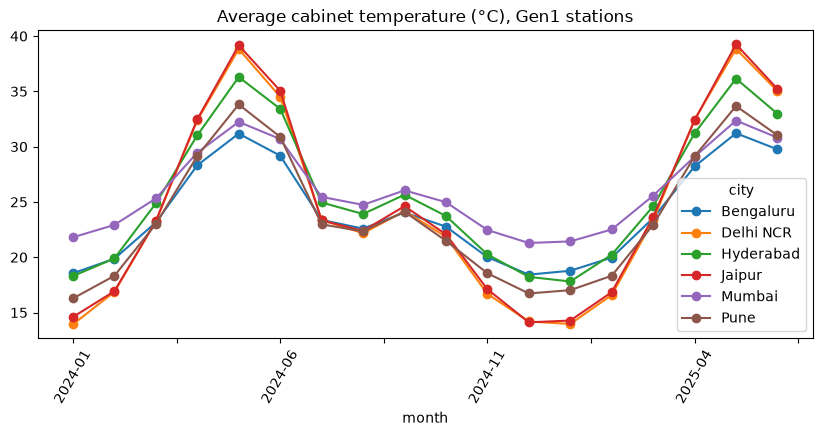

In [51]:
g1 = ok[ok["charger_generation"] == "Gen1"]

temp = g1.groupby(["month", "city"])["cabinet_temp_c"].mean().unstack()
print(temp.round(1))

temp.plot(marker="o", figsize=(10, 4))
plt.title("Average cabinet temperature (°C), Gen1 stations")
plt.xticks(rotation=60)
plt.show()

city     Bengaluru  Delhi NCR  Hyderabad  Jaipur  Mumbai  Pune
month                                                         
2024-01       88.0       88.0       88.0    88.0    88.0  88.0
2024-02       88.0       88.0       88.0    88.0    88.0  88.0
2024-03       88.0       88.0       88.0    88.0    88.0  88.0
2024-04       88.0       93.0       90.0    95.0    88.0  88.0
2024-05       91.0      122.0      108.0   126.0    89.0  95.0
2024-06       88.0      101.0       96.0   103.0    88.0  89.0
2024-07       88.0       88.0       88.0    88.0    88.0  88.0
2024-08       88.0       88.0       88.0    88.0    88.0  88.0
2024-09       88.0       88.0       88.0    88.0    88.0  88.0
2024-10       88.0       88.0       88.0    88.0    88.0  88.0
2024-11       88.0       88.0       88.0    88.0    88.0  88.0
2024-12       88.0       88.0       88.0    88.0    88.0  88.0
2025-01       88.0       88.0       88.0    88.0    88.0  88.0
2025-02       88.0       88.0       88.0    88.0    88.

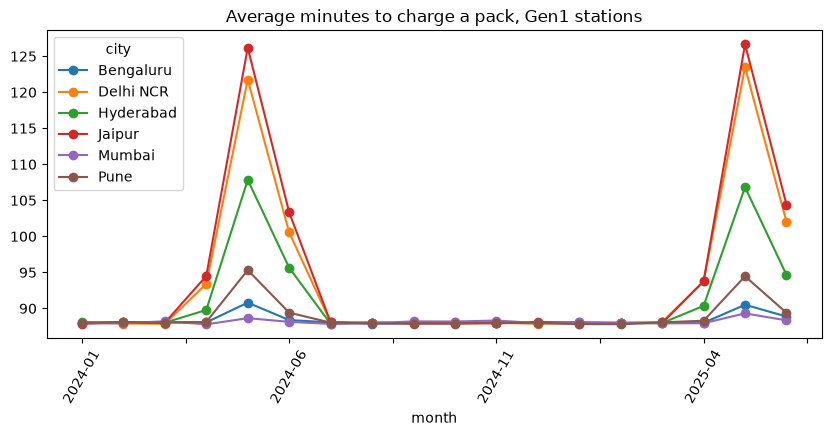

In [52]:
charge = g1.groupby(["month", "city"])["avg_charge_minutes"].mean().unstack()
print(charge.round(0))

charge.plot(marker="o", figsize=(10, 4))
plt.title("Average minutes to charge a pack, Gen1 stations")
plt.xticks(rotation=60)
plt.show()

In [53]:
hot = ok[ok["month"].isin(["2024-05", "2025-05"])]

print("Average minutes to charge a pack (May 2024 and May 2025):")
print(hot.groupby(["city", "charger_generation"])["avg_charge_minutes"].mean().unstack().round(0))

print()
print("Average cabinet temperature, °C:")
print(hot.groupby(["city", "charger_generation"])["cabinet_temp_c"].mean().unstack().round(1))

Average minutes to charge a pack (May 2024 and May 2025):
charger_generation   Gen1  Gen2  Gen3
city                                 
Bengaluru            91.0  64.0  42.0
Delhi NCR           123.0  68.0  43.0
Hyderabad           107.0  67.0  42.0
Jaipur              126.0  69.0  43.0
Mumbai               89.0  64.0  42.0
Pune                 95.0  65.0  42.0

Average cabinet temperature, °C:
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru           31.2  31.2  31.2
Delhi NCR           38.8  38.8  38.8
Hyderabad           36.2  36.2  36.1
Jaipur              39.2  39.2  39.3
Mumbai              32.3  32.3  32.4
Pune                33.7  33.7  33.7


In [54]:
hot2 = hot.dropna(subset=["charged_2w_min"]).copy()
hot2["empty_shelf"] = hot2["charged_2w_min"] == 0

print("Share of hours with NO charged 2-wheeler battery at some point (%):")
print((hot2.groupby(["city", "charger_generation"])["empty_shelf"].mean().unstack() * 100).round(1))

Share of hours with NO charged 2-wheeler battery at some point (%):
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru            1.5   0.6   0.3
Delhi NCR           21.6   0.8   0.2
Hyderabad            9.3   0.5   0.3
Jaipur              24.1   0.6   0.5
Mumbai               0.3   0.2   0.3
Pune                 0.8   0.1   0.1


In [55]:
g = swaps.groupby("rider_id", observed=True)["event_ts"].agg(["min", "max", "size"])
g.index = g.index.astype(str)
g.columns = ["first_ts", "last_ts", "n_attempts"]

r = riders.set_index("rider_id").join(g)

print("Riders with no swap attempts at all:", r["first_ts"].isna().sum())
print("Signup dates:", r["signup_date"].min().date(), "to", r["signup_date"].max().date())
print()
print("Days between signup and first attempt:")
print((r["first_ts"].dt.normalize() - r["signup_date"]).dt.days.describe().round(1))
print()
print("Attempts per rider:")
print(r["n_attempts"].describe().round(1))

Riders with no swap attempts at all: 59


AttributeError: 'str' object has no attribute 'date'

In [56]:
riders["signup_date"] = pd.to_datetime(riders["signup_date"])
r["signup_date"] = pd.to_datetime(r["signup_date"])
print("Converted. Type is now:", r["signup_date"].dtype)

Converted. Type is now: datetime64[us]


In [57]:
print("Riders with no swap attempts at all:", r["first_ts"].isna().sum())
print("Signup dates:", r["signup_date"].min().date(), "to", r["signup_date"].max().date())
print()
print("Days between signup and first attempt:")
print((r["first_ts"].dt.normalize() - r["signup_date"]).dt.days.describe().round(1))
print()
print("Attempts per rider:")
print(r["n_attempts"].describe().round(1))

Riders with no swap attempts at all: 59
Signup dates: 2023-03-08 to 2025-06-30

Days between signup and first attempt:
count    19941.0
mean        30.4
std         71.2
min          0.0
25%          0.0
50%          1.0
75%          2.0
max        311.0
dtype: float64

Attempts per rider:
count    19941.0
mean       191.3
std        163.6
min          1.0
25%         56.0
50%        149.0
75%        287.0
max        936.0
Name: n_attempts, dtype: float64


In [58]:
first_map = g["first_ts"]
days_since_first = (swaps["event_ts"] - swaps["rider_id"].astype(str).map(first_map)).dt.days

later = swaps[(days_since_first >= 30) & (days_since_first < 90)].groupby("rider_id", observed=True).size()
later.index = later.index.astype(str)

r["attempts_day30_90"] = later.reindex(r.index).fillna(0).astype(int)
r["churned"] = r["attempts_day30_90"] == 0

eligible = r[r["first_ts"] <= "2025-03-31"].copy()
print("Riders we can judge:", len(eligible))
print("Share who churned (%):", round(eligible["churned"].mean() * 100, 1))

by_month = eligible.groupby(eligible["first_ts"].dt.to_period("M").astype(str)).agg(
    riders=("churned", "size"), churn_pct=("churned", "mean"))
by_month["churn_pct"] = (by_month["churn_pct"] * 100).round(1)
by_month

Riders we can judge: 16255
Share who churned (%): 10.9


,riders,churn_pct
first_ts,,
2024-01,4182,7.3
2024-02,568,12.3
2024-03,600,10.7
2024-04,660,14.8
2024-05,717,18.4
2024-06,717,13.1
2024-07,804,10.3
2024-08,856,10.5
2024-09,869,11.9


In [59]:
new = r[(r["signup_date"] >= "2024-01-01") & (r["first_ts"].notna()) & (r["first_ts"] <= "2025-03-31")].copy()
new["signup_month"] = new["signup_date"].dt.to_period("M").astype(str)

print("True new riders we can judge:", len(new))
print("Share who churned (%):", round(new["churned"].mean() * 100, 1))
print()

by_month = new.groupby("signup_month").agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
by_month["churn_pct"] = (by_month["churn_pct"] * 100).round(1)
by_month

True new riders we can judge: 12655
Share who churned (%): 12.2



,riders,churn_pct
signup_month,,
2024-01,599,12.5
2024-02,566,12.4
2024-03,599,11.4
2024-04,662,14.7
2024-05,721,18.3
2024-06,716,13.1
2024-07,809,10.0
2024-08,854,10.9
2024-09,867,11.6


In [60]:
sw = swaps[["rider_id", "event_ts", "service_failure", "queue_wait_sec"]].copy()
sw["rider_id"] = sw["rider_id"].astype(str)
sw = sw[sw["rider_id"].isin(new.index)]
sw["days"] = (sw["event_ts"] - sw["rider_id"].map(new["first_ts"])).dt.total_seconds() / 86400
w1 = sw[sw["days"] < 7]

f = w1.groupby("rider_id").agg(
    attempts_w1=("event_ts", "size"),
    fails_w1=("service_failure", "sum"),
    avg_wait_w1=("queue_wait_sec", "mean"),
)
new = new.join(f)

new["fails_bucket"] = pd.cut(new["fails_w1"], [-1, 0, 1, 2, 1000], labels=["0 failures", "1 failure", "2 failures", "3+ failures"])
out = new.groupby("fails_bucket", observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
out["churn_pct"] = (out["churn_pct"] * 100).round(1)
out

,riders,churn_pct
fails_bucket,,
0 failures,8988,11.0
1 failure,2932,13.3
2 failures,588,19.6
3+ failures,147,28.6


In [61]:
new["partner_id"] = new["partner_id"].fillna("Independent")
new["is_fleet"] = np.where(new["partner_id"] == "Independent", "Independent", "Fleet-affiliated")

for col in ["signup_channel", "plan_type", "vehicle_class", "city_clean", "is_fleet", "age_band", "kyc_verified"]:
    t = new.groupby(col, dropna=False).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
    t["churn_pct"] = (t["churn_pct"] * 100).round(1)
    print(col)
    print(t)
    print()

signup_channel
                    riders  churn_pct
signup_channel                       
app_store             2699       10.6
field_agent           2619       11.8
partner_onboarding    5860       13.1
referral              1477       11.7

plan_type
                riders  churn_pct
plan_type                        
partner_billed    7747       12.9
pay_as_you_go     3421       11.0
prepaid_pack      1487       11.0

vehicle_class
               riders  churn_pct
vehicle_class                   
2W              10828       11.9
3W               1827       13.5

city_clean
            riders  churn_pct
city_clean                   
Bengaluru     2781       11.2
Delhi NCR     2491       12.4
Hyderabad     2175       13.0
Jaipur        1585       13.6
Mumbai        1804       10.7
Pune          1819       12.4

is_fleet
                  riders  churn_pct
is_fleet                           
Fleet-affiliated    7747       12.9
Independent         4908       11.0

age_band
          rid

In [62]:
 
sw2 = swaps[["rider_id", "event_ts", "event_type", "amount_charged_inr", "km_clean", "soh_out_pct"]].copy()
sw2["rider_id"] = sw2["rider_id"].astype(str)
sw2 = sw2[sw2["rider_id"].isin(new.index)]
sw2["days"] = (sw2["event_ts"] - sw2["rider_id"].map(new["first_ts"])).dt.total_seconds() / 86400
w1c = sw2[(sw2["days"] < 7) & (sw2["event_type"] == "swap_completed")]

f2 = w1c.groupby("rider_id").agg(
    price_w1=("amount_charged_inr", "mean"),
    range_w1=("km_clean", "mean"),
    soh_w1=("soh_out_pct", "mean"),
)
new = new.drop(columns=[c for c in f2.columns if c in new.columns]).join(f2)

 
t = tickets[["rider_id", "created_ts", "resolution_status"]].copy()
t = t[t["rider_id"].isin(new.index)]
t["days"] = (t["created_ts"] - t["rider_id"].map(new["first_ts"])).dt.total_seconds() / 86400
t30 = t[(t["days"] >= 0) & (t["days"] < 30)]

tk = t30.groupby("rider_id").agg(
    tickets_30d=("created_ts", "size"),
    unresolved_30d=("resolution_status", lambda s: (s == "unresolved").sum()),
)
new = new.drop(columns=[c for c in tk.columns if c in new.columns]).join(tk)
new[["tickets_30d", "unresolved_30d"]] = new[["tickets_30d", "unresolved_30d"]].fillna(0)
print("Done. Riders:", len(new))

TypeError: operation 'sub' not supported for dtype 'str' with dtype 'datetime64[us]'

In [63]:
tickets["created_ts"] = pd.to_datetime(tickets["created_ts"])

for c in ["commissioned_date", "decommissioned_date", "firmware_updated_date", "competitor_within_1_5km_since"]:
    stations[c] = pd.to_datetime(stations[c])

for c in ["manufacture_date", "commission_date", "retired_date"]:
    batteries[c] = pd.to_datetime(batteries[c])

city_ctx["date"] = pd.to_datetime(city_ctx["date"])

for c in ["contract_start_date", "amendment_date"]:
    partners[c] = pd.to_datetime(partners[c])

print("Ticket time type is now:", tickets["created_ts"].dtype)

Ticket time type is now: datetime64[us]


In [64]:
t = tickets[["rider_id", "created_ts", "resolution_status"]].copy()
t = t[t["rider_id"].isin(new.index)]
t["days"] = (t["created_ts"] - t["rider_id"].map(new["first_ts"])).dt.total_seconds() / 86400
t30 = t[(t["days"] >= 0) & (t["days"] < 30)]

tk = t30.groupby("rider_id").agg(
    tickets_30d=("created_ts", "size"),
    unresolved_30d=("resolution_status", lambda s: (s == "unresolved").sum()),
)
new = new.drop(columns=[c for c in tk.columns if c in new.columns]).join(tk)
new[["tickets_30d", "unresolved_30d"]] = new[["tickets_30d", "unresolved_30d"]].fillna(0)

print("Done. Riders:", len(new))
print("Columns for first-week factors present:", [c for c in ["price_w1", "range_w1", "soh_w1"] if c in new.columns])

Done. Riders: 12655
Columns for first-week factors present: ['price_w1', 'range_w1', 'soh_w1']


In [65]:
def churn_by(col, q=4):
    groups = pd.qcut(new[col], q, duplicates="drop")
    out = new.groupby(groups, observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
    out["churn_pct"] = (out["churn_pct"] * 100).round(1)
    return out

for col in ["avg_wait_w1", "price_w1", "range_w1", "soh_w1"]:
    print(col)
    print(churn_by(col))
    print()

tick = new.groupby(new["tickets_30d"].clip(upper=3)).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
tick["churn_pct"] = (tick["churn_pct"] * 100).round(1)
print("Tickets raised in first 30 days (3 means 3 or more):")
print(tick)
print()

unres = new.groupby(new["unresolved_30d"].clip(upper=2)).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
unres["churn_pct"] = (unres["churn_pct"] * 100).round(1)
print("Unresolved tickets in first 30 days (2 means 2 or more):")
print(unres)

avg_wait_w1
                    riders  churn_pct
avg_wait_w1                          
(0.999, 199.143]      3165       13.3
(199.143, 234.167]    3165       11.3
(234.167, 275.182]    3162       10.8
(275.182, 787.0]      3163       13.1

price_w1
                riders  churn_pct
price_w1                         
(45.688, 57.2]    3531       13.8
(57.2, 60.0]      3323       11.6
(60.0, 65.0]      2835       10.2
(65.0, 125.0]     2959       12.5

range_w1
                 riders  churn_pct
range_w1                          
(36.642, 57.95]    3163       11.8
(57.95, 64.5]      3165       11.9
(64.5, 71.491]     3158       11.9
(71.491, 122.2]    3162       12.9

soh_w1
                  riders  churn_pct
soh_w1                             
(75.149, 88.774]    3162       11.1
(88.774, 92.491]    3162       11.6
(92.491, 95.5]      3165       12.1
(95.5, 100.0]       3159       13.7

Tickets raised in first 30 days (3 means 3 or more):
             riders  churn_pct
tickets_30d      

In [67]:
 
w30 = sw[sw["days"] < 30]
f30 = w30.groupby("rider_id").agg(attempts_30d=("event_ts", "size"), fails_30d=("service_failure", "sum"))
new = new.drop(columns=[c for c in f30.columns if c in new.columns]).join(f30)
new["fail_rate_30d"] = new["fails_30d"] / new["attempts_30d"]

new["fail_share_bucket"] = pd.cut(new["fail_rate_30d"], [-0.001, 0, 0.05, 0.10, 0.25, 1.0],
                                  labels=["none", "up to 5%", "5-10%", "10-25%", "over 25%"])
a = new.groupby("fail_share_bucket", observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
a["churn_pct"] = (a["churn_pct"] * 100).round(1)
print("Churn by share of attempts that failed (first 30 days):")
print(a)
print()
new["spring_2024_signup"] = new["signup_month"].isin(["2024-04", "2024-05", "2024-06"])
new["any_fail_w1"] = new["fails_w1"] > 0
b = new.groupby(["spring_2024_signup", "any_fail_w1"]).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
b["churn_pct"] = (b["churn_pct"] * 100).round(1)
print("Churn by signup season and first-week failure:")
print(b)
print()
print("Share of riders with a first-week failure (%):")
print((new.groupby("spring_2024_signup")["any_fail_w1"].mean() * 100).round(1))

Churn by share of attempts that failed (first 30 days):
                   riders  churn_pct
fail_share_bucket                   
none                 3987       15.7
up to 5%             3992        3.6
5-10%                2824       11.6
10-25%               1686       20.9
over 25%              166       51.8

Churn by signup season and first-week failure:
                                riders  churn_pct
spring_2024_signup any_fail_w1                   
False              False          7837       10.9
                   True           2719       13.4
True               False          1151       12.0
                   True            948       19.5

Share of riders with a first-week failure (%):
spring_2024_signup
False    25.8
True     45.2
Name: any_fail_w1, dtype: float64


In [68]:
new["activity_bucket"] = pd.cut(new["attempts_30d"], [0, 3, 10, 30, 1000],
                                labels=["1-3 attempts", "4-10", "11-30", "over 30"])

print("Typical number of attempts in first 30 days, by failure-share group:")
print(new.groupby("fail_share_bucket", observed=True)["attempts_30d"].median())
print()

c = new.groupby("activity_bucket", observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
c["churn_pct"] = (c["churn_pct"] * 100).round(1)
print("Churn by how active the rider was in the first 30 days:")
print(c)
print()

p = new.pivot_table(index="activity_bucket", columns="fail_share_bucket", values="churned", aggfunc="mean", observed=True) * 100
n = new.pivot_table(index="activity_bucket", columns="fail_share_bucket", values="churned", aggfunc="size", observed=True)
print("Churn % within each activity level:")
print(p.round(1))
print()
print("Number of riders behind each cell:")
print(n)

Typical number of attempts in first 30 days, by failure-share group:
fail_share_bucket
none        27.0
up to 5%    31.0
5-10%       30.0
10-25%      26.0
over 25%    15.0
Name: attempts_30d, dtype: float64

Churn by how active the rider was in the first 30 days:
                 riders  churn_pct
activity_bucket                   
1-3 attempts        217       63.6
4-10                515       61.6
11-30              7015       13.4
over 30            4908        2.9

Churn % within each activity level:
fail_share_bucket  none  up to 5%  5-10%  10-25%  over 25%
activity_bucket                                           
1-3 attempts       60.8       NaN    NaN     NaN      87.0
4-10               60.0       NaN   62.5    63.2      67.4
11-30              12.9       5.6   17.1    21.3      40.2
over 30             2.1       1.7    4.7     5.2       0.0

Number of riders behind each cell:
fail_share_bucket    none  up to 5%   5-10%  10-25%  over 25%
activity_bucket                      

In [69]:
s3 = swaps[["rider_id", "station_id", "event_ts", "tariff_code"]].copy()
s3["rider_id"] = s3["rider_id"].astype(str)
s3 = s3[s3["rider_id"].isin(new.index)]
s3["days"] = (s3["event_ts"] - s3["rider_id"].map(new["first_ts"])).dt.total_seconds() / 86400
s3 = s3[s3["days"] < 30]

comp_date = stations.set_index("station_id")["competitor_within_1_5km_since"]
s3["comp_since"] = s3["station_id"].astype(str).map(comp_date)
s3["competitor_open"] = s3["comp_since"].notna() & (s3["event_ts"] >= s3["comp_since"])
s3["peak"] = s3["tariff_code"].astype(str) == "PEAK"

x = s3.groupby("rider_id").agg(comp_share=("competitor_open", "mean"), peak_share=("peak", "mean"))
new = new.drop(columns=[c for c in x.columns if c in new.columns]).join(x)

new["comp_group"] = pd.cut(new["comp_share"], [-0.001, 0, 0.999, 1.0],
                           labels=["no competitor nearby", "mixed", "competitor nearby all month"])
new["peak_group"] = pd.cut(new["peak_share"], [-0.001, 0, 0.25, 1.0],
                           labels=["no peak-priced swaps", "up to 25%", "over 25%"])
new["failure_level"] = np.where(new["fail_rate_30d"] > 0.05, "failures over 5%", "failures 5% or less")

base = new[new["attempts_30d"] >= 11]
print("Riders compared:", len(base))
print()

for col in ["comp_group", "peak_group"]:
    t = base.groupby(col, observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
    t["churn_pct"] = (t["churn_pct"] * 100).round(1)
    print(col, "(all riders)")
    print(t)
    print()
    t2 = base.groupby([col, "failure_level"], observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
    t2["churn_pct"] = (t2["churn_pct"] * 100).round(1)
    print(col, "(split by failure level)")
    print(t2)
    print()

Riders compared: 11923

comp_group (all riders)
                             riders  churn_pct
comp_group                                    
no competitor nearby          11310        9.1
mixed                           607        7.9
competitor nearby all month       6       33.3

comp_group (split by failure level)
                                                 riders  churn_pct
comp_group                  failure_level                         
no competitor nearby        failures 5% or less    7046        6.2
                            failures over 5%       4264       14.0
mixed                       failures 5% or less     413        6.1
                            failures over 5%        194       11.9
competitor nearby all month failures 5% or less       6       33.3

peak_group (all riders)
                      riders  churn_pct
peak_group                             
no peak-priced swaps   11022        9.3
up to 25%                 43        2.3
over 25%                 8

           riders  churn_pct
fail_band                   
up to 5%     3992        3.6
5-10%        2808       11.3
10-25%       1553       17.3
over 25%       97       36.1


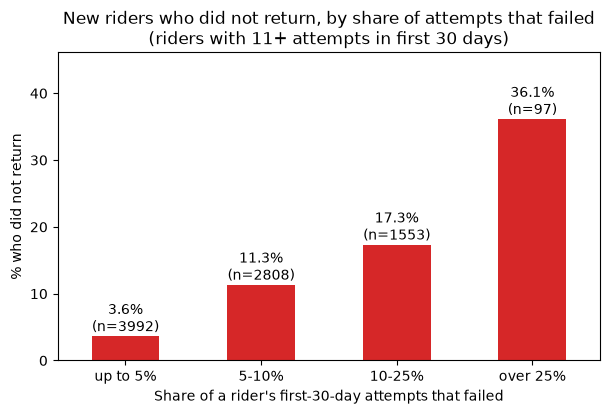

Saved.


In [70]:
core = new[new["attempts_30d"] >= 11].copy()
core["fail_band"] = pd.cut(core["fail_rate_30d"], [0, 0.05, 0.10, 0.25, 1.0],
                           labels=["up to 5%", "5-10%", "10-25%", "over 25%"])

t = core.groupby("fail_band", observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
t["churn_pct"] = (t["churn_pct"] * 100).round(1)
print(t)

ax = t["churn_pct"].plot(kind="bar", figsize=(7, 4), color="tab:red")
for i, (v, n) in enumerate(zip(t["churn_pct"], t["riders"])):
    ax.text(i, v + 0.8, f"{v}%\n(n={n})", ha="center")
plt.title("New riders who did not return, by share of attempts that failed\n(riders with 11+ attempts in first 30 days)")
plt.xlabel("Share of a rider's first-30-day attempts that failed")
plt.ylabel("% who did not return")
plt.xticks(rotation=0)
plt.ylim(0, t["churn_pct"].max() + 10)
plt.show()

new.to_pickle("clean/new_riders.pkl")
swaps.to_pickle("clean/swaps_clean.pkl")
print("Saved.")

In [72]:
comp = swaps[swaps["completed"]].copy()
comp["grid_tariff_inr_kwh"] = comp["grid_tariff_inr_kwh"].astype(float)
comp["energy_cost"] = comp["energy_to_recharge_kwh"] * comp["grid_tariff_inr_kwh"]

money = comp.groupby("month").agg(
    swaps=("event_id", "size"),
    revenue=("amount_charged_inr", "sum"),
    list_total=("list_price_inr", "sum"),
    discount_total=("discount_inr", "sum"),
    energy_cost=("energy_cost", "sum"),
)

 
rows = []
for m in pd.period_range("2024-01", "2025-06", freq="M"):
    start, end = m.start_time, m.end_time
    active = (stations["commissioned_date"] <= end) & (stations["decommissioned_date"].isna() | (stations["decommissioned_date"] >= start))
    cost = (stations.loc[active, "monthly_rent_inr"] + stations.loc[active, "monthly_maintenance_inr"]).sum()
    rows.append({"month": str(m), "stations_open": int(active.sum()), "station_cost": cost})
money = money.join(pd.DataFrame(rows).set_index("month"))

money["revenue_per_swap"] = money["revenue"] / money["swaps"]
money["list_price_per_swap"] = money["list_total"] / money["swaps"]
money["discount_per_swap"] = money["discount_total"] / money["swaps"]
money["energy_per_swap"] = money["energy_cost"] / money["swaps"]
money["station_cost_per_swap"] = money["station_cost"] / money["swaps"]
money["margin_per_swap"] = money["revenue_per_swap"] - money["energy_per_swap"] - money["station_cost_per_swap"]

money[["swaps", "stations_open", "list_price_per_swap", "discount_per_swap", "revenue_per_swap",
       "energy_per_swap", "station_cost_per_swap", "margin_per_swap"]].round(1)

,swaps,stations_open,list_price_per_swap,discount_per_swap,revenue_per_swap,energy_per_swap,station_cost_per_swap,margin_per_swap
month,,,,,,,,
2024-01,103508,90,64.5,4.6,59.9,22.0,20.4,17.5
2024-02,104437,90,64.5,4.6,59.9,21.9,20.2,17.8
2024-03,116148,90,64.4,4.6,59.9,21.7,18.2,20.0
2024-04,120117,90,64.5,4.5,60.0,21.6,17.6,20.8
2024-05,125454,90,64.4,4.5,59.9,21.3,16.8,21.7
2024-06,130880,90,64.3,4.5,59.8,21.0,16.1,22.7
2024-07,148611,90,69.9,4.9,65.0,20.9,14.2,30.0
2024-08,161688,100,69.9,4.9,65.0,20.6,14.7,29.7
2024-09,184051,108,69.5,4.9,64.7,20.5,13.8,30.4


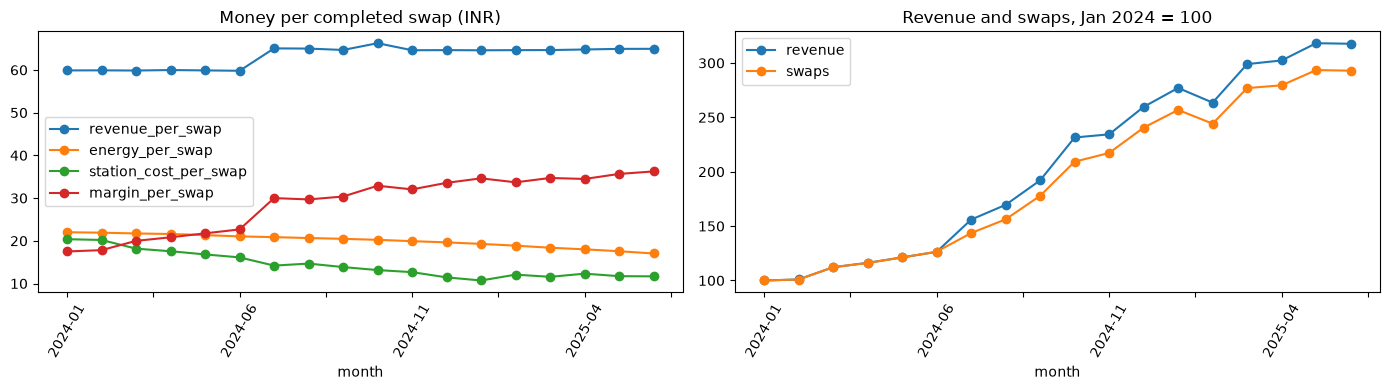

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

money[["revenue_per_swap", "energy_per_swap", "station_cost_per_swap", "margin_per_swap"]].plot(ax=ax[0], marker="o")
ax[0].set_title("Money per completed swap (INR)")
ax[0].tick_params(axis="x", rotation=60)

money[["revenue", "swaps"]].div(money[["revenue", "swaps"]].iloc[0]).mul(100).plot(ax=ax[1], marker="o")
ax[1].set_title("Revenue and swaps, Jan 2024 = 100")
ax[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [75]:
EOL = 70    

b = batteries.set_index("battery_id").copy()
b["soh_lost"] = (b["initial_soh_pct"] - b["current_soh_pct"]).clip(lower=0)
b["wear_cost_total"] = b["purchase_cost_inr"] * b["soh_lost"] / (b["initial_soh_pct"] - EOL)

n_issued = comp["battery_out_id"].astype(str).value_counts()
per_swap = b["wear_cost_total"] / n_issued.reindex(b.index)
per_swap = per_swap.replace([np.inf, -np.inf], np.nan)

comp["wear_cost"] = comp["battery_out_id"].astype(str).map(per_swap).astype(float)
print("Swaps with no wear figure:", comp["wear_cost"].isna().sum())
print("Average wear cost per swap (INR):", round(comp["wear_cost"].mean(), 2))

money["wear_per_swap"] = comp.groupby("month")["wear_cost"].mean()
money["margin_after_wear"] = money["margin_per_swap"] - money["wear_per_swap"]
money[["revenue_per_swap", "energy_per_swap", "station_cost_per_swap", "wear_per_swap", "margin_after_wear"]].round(1)

Swaps with no wear figure: 0
Average wear cost per swap (INR): 49.57


,revenue_per_swap,energy_per_swap,station_cost_per_swap,wear_per_swap,margin_after_wear
month,,,,,
2024-01,59.9,22.0,20.4,38.7,-21.2
2024-02,59.9,21.9,20.2,38.7,-20.9
2024-03,59.9,21.7,18.2,38.6,-18.6
2024-04,60.0,21.6,17.6,38.7,-17.9
2024-05,59.9,21.3,16.8,38.6,-16.9
2024-06,59.8,21.0,16.1,38.5,-15.8
2024-07,65.0,20.9,14.2,38.5,-8.5
2024-08,65.0,20.6,14.7,38.5,-8.8
2024-09,64.7,20.5,13.8,50.0,-19.6


In [76]:
comp["is_fleet"] = np.where(comp["partner_id"].astype(str) == "Independent", "Independent", "Fleet")
d = comp.groupby(["month", "is_fleet"])["discount_inr"].mean().unstack().round(1)
print("Average discount per swap (INR):")
print(d)
print()

comp["period"] = np.where(comp["month"] < "2024-11", "before Nov 2024", "Nov 2024 onwards")
p = comp.groupby(["partner_id", "period"], observed=True).agg(swaps=("event_id", "size"), discount=("discount_inr", "mean"))
p = p["discount"].unstack().round(1)
p["change"] = (p["Nov 2024 onwards"] - p["before Nov 2024"]).round(1)
print("Average discount per swap by partner:")
print(p.sort_values("change", ascending=False))

Average discount per swap (INR):
is_fleet  Fleet  Independent
month                       
2024-01     6.8          0.0
2024-02     6.8          0.0
2024-03     6.8          0.0
2024-04     6.8          0.0
2024-05     6.8          0.0
2024-06     6.8          0.0
2024-07     7.4          0.0
2024-08     7.4          0.0
2024-09     7.4          0.0
2024-10     7.4          0.0
2024-11     9.9          0.0
2024-12     9.9          0.0
2025-01    10.0          0.0
2025-02    10.0          0.0
2025-03    10.0          0.0
2025-04     9.9          0.0
2025-05     9.9          0.0
2025-06     9.9          0.0

Average discount per swap by partner:
period       Nov 2024 onwards  before Nov 2024  change
partner_id                                            
FP-03                    18.9              7.8    11.1
FP-04                     8.8              8.4     0.4
FP-02                    10.1              9.7     0.4
FP-09                     7.7              7.3     0.4
FP-01             

In [77]:
p2 = p.copy()
p2.index = p2.index.astype(str)

cnt = comp.groupby("partner_id", observed=True).size()
cnt.index = cnt.index.astype(str)
p2["swaps"] = cnt
p2["share_of_swaps_pct"] = (cnt / cnt.sum() * 100).round(1)

info = partners.set_index("partner_id")[["partner_name", "partner_segment", "contract_type",
                                         "discount_pct", "amendment_date", "discount_pct_after_amendment"]]
out = p2.join(info).sort_values("change", ascending=False)
print(out.to_string())

             Nov 2024 onwards  before Nov 2024  change    swaps  share_of_swaps_pct partner_name partner_segment  contract_type  discount_pct amendment_date  discount_pct_after_amendment
partner_id                                                                                                                                                                                
FP-03                    18.9              7.8    11.1   549390                15.3      ZipDrop  quick_commerce  volume_tiered          12.0     2024-11-01                          28.0
FP-04                     8.8              8.4     0.4   131334                 3.7     CargoTuk        cargo_3w   pay_per_swap           8.0            NaT                           NaN
FP-02                    10.1              9.7     0.4   296209                 8.3   ParcelNest  ecom_logistics   pay_per_swap          15.0            NaT                           NaN
FP-09                     7.7              7.3     0.4    53120  

In [78]:
b2 = batteries.copy()
b2["issued_swaps"] = b2["battery_id"].map(n_issued)
b2["soh_lost"] = (b2["initial_soh_pct"] - b2["current_soh_pct"]).clip(lower=0)
b2["lost_per_100_swaps"] = b2["soh_lost"] / b2["issued_swaps"] * 100
b2["commission_qtr"] = b2["commission_date"].dt.to_period("Q").astype(str)

g = b2.groupby(["supplier", "pack_type"]).agg(
    batteries=("battery_id", "size"),
    avg_swaps=("issued_swaps", "mean"),
    health_lost=("soh_lost", "mean"),
    lost_per_100_swaps=("lost_per_100_swaps", "mean"),
    cost_inr=("purchase_cost_inr", "mean"),
)
print(g.round(2))
print()
print("Health points lost per 100 swaps, by supplier and the quarter the battery entered service:")
print(b2.groupby(["commission_qtr", "supplier"])["lost_per_100_swaps"].mean().unstack().round(2))

                    batteries  avg_swaps  health_lost  lost_per_100_swaps  \
supplier pack_type                                                          
Amptek   2W_2.1kWh       1098     643.06        19.24                3.00   
         3W_4.8kWh        209     377.38        12.69                3.37   
Cellora  2W_2.1kWh       3035     643.15        19.21                2.99   
         3W_4.8kWh        520     378.66        12.67                3.36   
Kyron    2W_2.1kWh       1385     401.71        38.67                9.65   
         3W_4.8kWh        253     381.38        17.90                4.70   

                    cost_inr  
supplier pack_type            
Amptek   2W_2.1kWh  31995.05  
         3W_4.8kWh  67822.26  
Cellora  2W_2.1kWh  31983.39  
         3W_4.8kWh  67957.39  
Kyron    2W_2.1kWh  31981.68  
         3W_4.8kWh  67920.95  

Health points lost per 100 swaps, by supplier and the quarter the battery entered service:
supplier        Amptek  Cellora  Kyron
comm

In [79]:
cols = ["partner_id", "partner_name", "contract_type", "discount_pct", "amendment_date",
        "discount_pct_after_amendment", "peak_surcharge_billable", "payment_terms_days"]
print(partners[cols].to_string(index=False))

partner_id partner_name contract_type  discount_pct amendment_date  discount_pct_after_amendment peak_surcharge_billable  payment_terms_days
     FP-01     FeastFly volume_tiered          10.0            NaT                           NaN                       Y                  30
     FP-02   ParcelNest  pay_per_swap          15.0            NaT                           NaN                       Y                  30
     FP-03      ZipDrop volume_tiered          12.0     2024-11-01                          28.0                       N                  45
     FP-04     CargoTuk  pay_per_swap           8.0            NaT                           NaN                       Y                  30
     FP-05   Swiggle Go volume_tiered          11.0            NaT                           NaN                       N                  30
     FP-06    RideMitra  pay_per_swap           6.0            NaT                           NaN                       Y                  15
     FP-07   

In [80]:
comp["partner_str"] = comp["partner_id"].astype(str)
comp["period"] = np.where(comp["month"] < "2024-11", "before Nov 2024", "Nov 2024 onwards")
comp["station_cost_alloc"] = comp["month"].map(money["station_cost_per_swap"])
comp["margin_pre_wear"] = comp["amount_charged_inr"] - comp["energy_cost"] - comp["station_cost_alloc"]

v = comp.groupby(["partner_str", "period"]).agg(
    swaps=("event_id", "size"),
    revenue_per_swap=("amount_charged_inr", "mean"),
    margin_per_swap=("margin_pre_wear", "mean"),
    total_margin=("margin_pre_wear", "sum"),
).round(1)
print(v["margin_per_swap"].unstack().assign(change=lambda d: (d["Nov 2024 onwards"] - d["before Nov 2024"]).round(1)))
print()
print("Total margin since Nov 2024 (INR lakh), before battery wear:")
print((v.xs("Nov 2024 onwards", level="period")["total_margin"] / 1e5).round(1).sort_values(ascending=False))

z = comp[(comp["partner_str"] == "FP-03") & (comp["period"] == "Nov 2024 onwards")]
extra = (z["discount_inr"].mean() - comp[(comp["partner_str"] == "FP-03") & (comp["period"] == "before Nov 2024")]["discount_inr"].mean()) * len(z)
print()
print("Extra discount given to ZipDrop since Nov 2024 (INR lakh):", round(extra / 1e5, 1))

period       Nov 2024 onwards  before Nov 2024  change
partner_str                                           
FP-01                    35.0             23.2    11.8
FP-02                    28.5             19.7     8.8
FP-03                    18.7             20.8    -2.1
FP-04                    50.2             37.7    12.5
FP-05                    31.1             22.1     9.0
FP-06                    35.2             25.2    10.0
FP-07                    35.4             23.7    11.7
FP-08                    36.7             24.9    11.8
FP-09                    51.1             38.9    12.2
FP-10                    30.7             21.7     9.0
FP-11                    32.2             23.0     9.2
FP-12                    35.9             25.8    10.1
Independent              41.1             29.7    11.4

Total margin since Nov 2024 (INR lakh), before battery wear:
partner_str
Independent    304.5
FP-01          109.9
FP-03           63.0
FP-02           50.7
FP-05           4

In [81]:
ky = b2[b2["supplier"] == "Kyron"]
lots = ky.groupby(["manufacturing_lot", "pack_type"]).agg(
    batteries=("battery_id", "size"),
    first_in_service=("commission_date", "min"),
    avg_swaps=("issued_swaps", "mean"),
    lost_per_100_swaps=("lost_per_100_swaps", "mean"),
).round(2)
print(lots.sort_values("lost_per_100_swaps", ascending=False).to_string())
print()
print(b2.groupby(["commission_qtr", "supplier"])["lost_per_100_swaps"].mean().unstack().round(2).to_string())

                             batteries first_in_service  avg_swaps  lost_per_100_swaps
manufacturing_lot pack_type                                                           
KY-2408           2W_2.1kWh        471       2024-09-10     401.69                9.66
KY-2409           2W_2.1kWh        462       2024-09-10     401.37                9.65
KY-2407           2W_2.1kWh        452       2024-09-10     402.08                9.64
                  3W_4.8kWh         28       2024-07-01     382.82                7.97
KY-2408           3W_4.8kWh         29       2024-08-01     381.86                7.81
KY-2409           3W_4.8kWh         19       2024-09-04     384.63                7.76
KY-2410           3W_4.8kWh         17       2024-10-02     366.82                3.56
KY-2418           3W_4.8kWh         14       2025-06-01     371.14                3.41
KY-2412           3W_4.8kWh         21       2024-12-01     379.71                3.36
KY-2414           3W_4.8kWh         16     

C:\Users\vjsro\AppData\Local\Temp\ipykernel_17636\283379173.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


         ZipDrop  FeastFly  Everyone else
month                                    
2024-01    15654     15531          72323
2024-02    15853     15754          72830
2024-03    17553     17741          80854
2024-04    17837     17613          84667
2024-05    18566     17737          89151
2024-06    19311     18684          92885
2024-07    21732     21049         105830
2024-08    24649     22110         114929
2024-09    28485     25341         130225
2024-10    33328     30899         152324
2024-11    34946     32278         157633
2024-12    39080     35741         174133
2025-01    42018     38070         185746
2025-02    39514     36145         177091
2025-03    44867     41433         200330
2025-04    44125     42136         203000
2025-05    45873     44179         213696
2025-06    45999     43926         213271


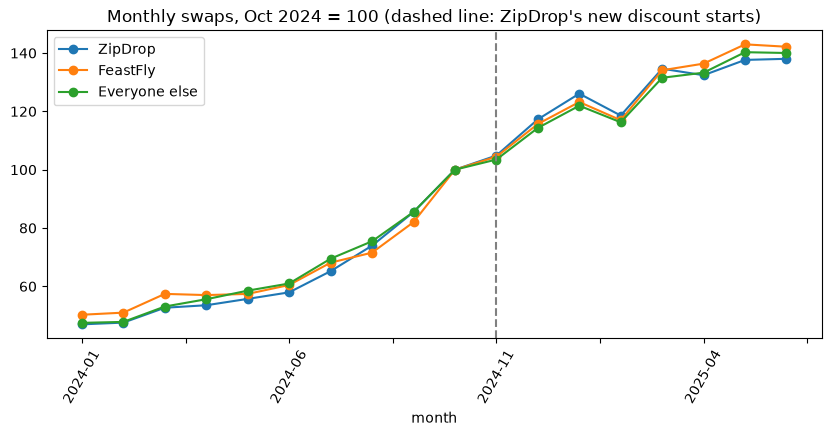

In [82]:
m = comp.groupby(["month", "partner_str"]).size().unstack()

view = pd.DataFrame({
    "ZipDrop": m["FP-03"],
    "FeastFly": m["FP-01"],
    "Everyone else": m.drop(columns=["FP-03", "FP-01"]).sum(axis=1),
})
print(view)

indexed = view / view.loc["2024-10"] * 100
ax = indexed.plot(marker="o", figsize=(10, 4))
ax.axvline(list(view.index).index("2024-11"), color="gray", linestyle="--")
plt.title("Monthly swaps, Oct 2024 = 100 (dashed line: ZipDrop's new discount starts)")
plt.xticks(rotation=60)
plt.show()

In [83]:
bad_lots = ["KY-2407", "KY-2408", "KY-2409"]
bb = b2[b2["manufacturing_lot"].isin(bad_lots)].copy()

normal = b2[b2["supplier"].isin(["Amptek", "Cellora"])].groupby("pack_type")["lost_per_100_swaps"].mean()
bb["normal_rate"] = bb["pack_type"].map(normal)
bb["excess_health_lost"] = (bb["soh_lost"] - bb["normal_rate"] * bb["issued_swaps"] / 100).clip(lower=0)
bb["excess_cost_inr"] = bb["purchase_cost_inr"] * bb["excess_health_lost"] / (bb["initial_soh_pct"] - EOL)

print("Packs in the three weak Kyron lots:", len(bb), "of", len(b2), "total")
print("Extra health points lost per pack vs a normal pack:", round(bb["excess_health_lost"].mean(), 1))
print("Extra battery wear cost (INR lakh):", round(bb["excess_cost_inr"].sum() / 1e5, 1))
print()
print(bb["retirement_reason"].value_counts(dropna=False))

Packs in the three weak Kyron lots: 1461 of 6500 total
Extra health points lost per pack vs a normal pack: 26.1
Extra battery wear cost (INR lakh): 434.7

retirement_reason
end_of_life    1438
NaN              23
Name: count, dtype: int64


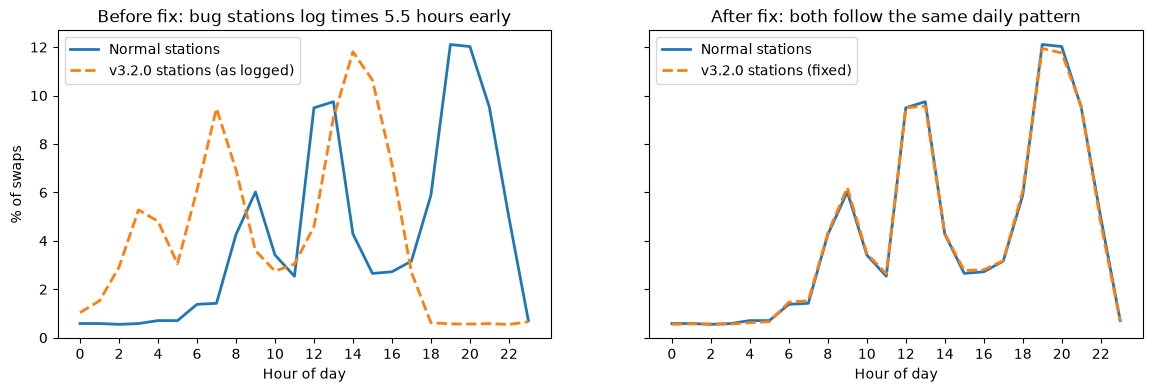

saved: 01_clock_bug_before_after


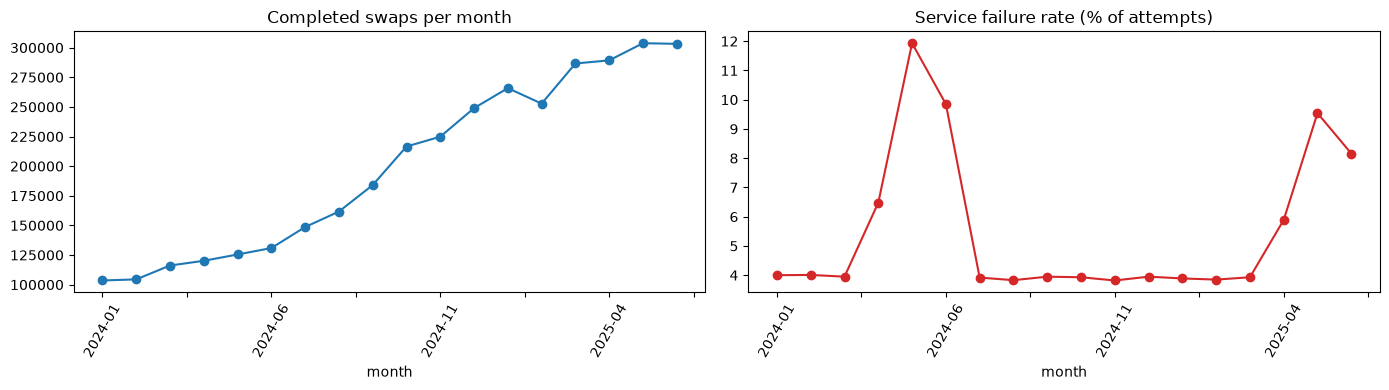

saved: 02_network_trends


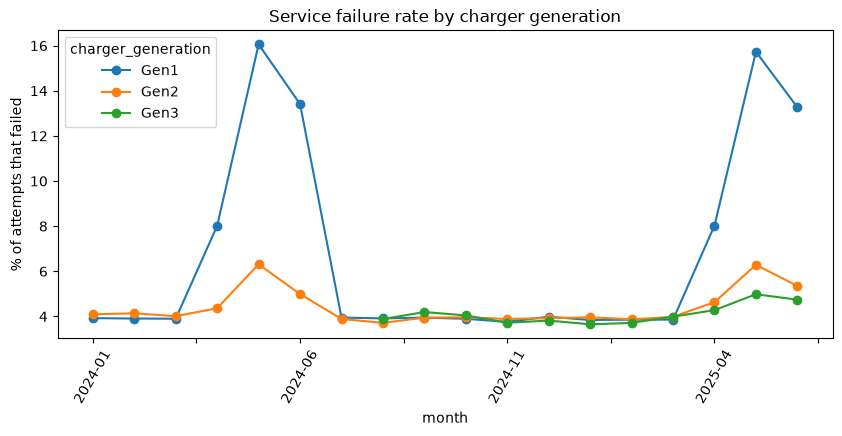

saved: 03_failures_by_charger_generation


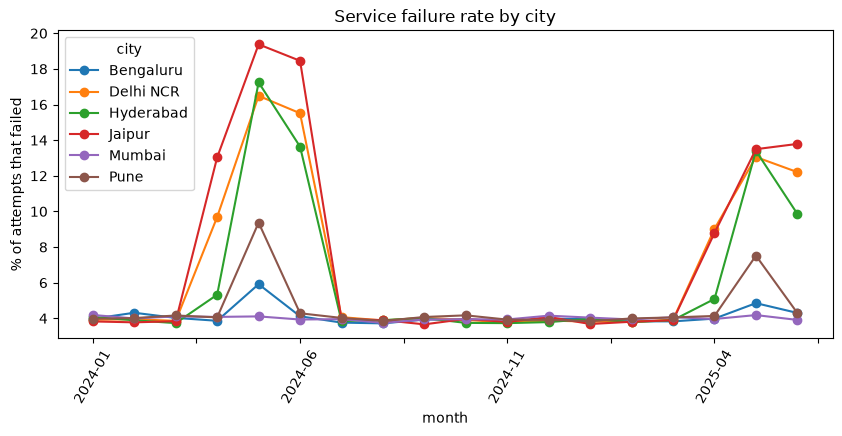

saved: 04_failures_by_city


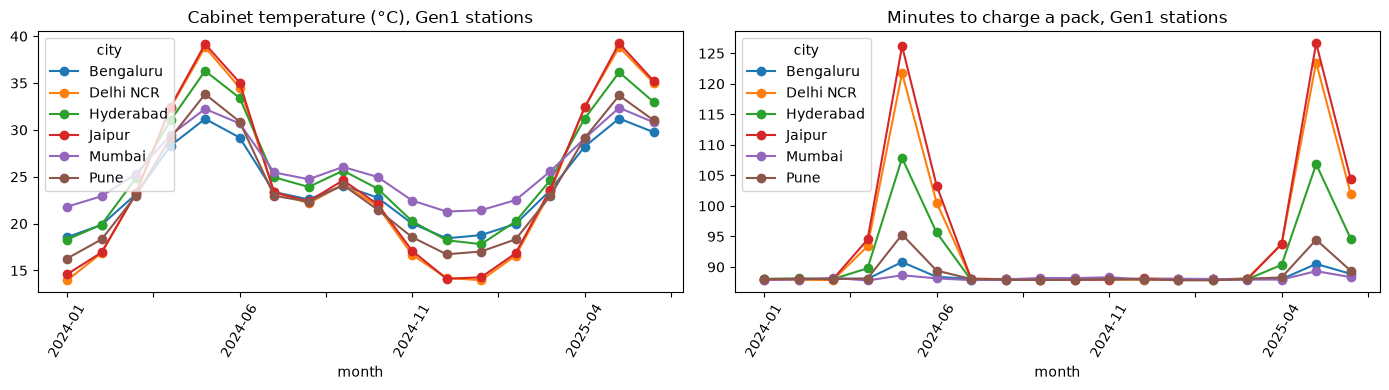

saved: 05_heat_and_charging_time


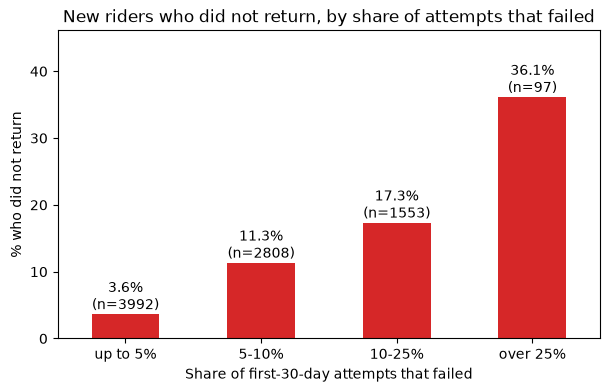

saved: 06_churn_by_failure_share


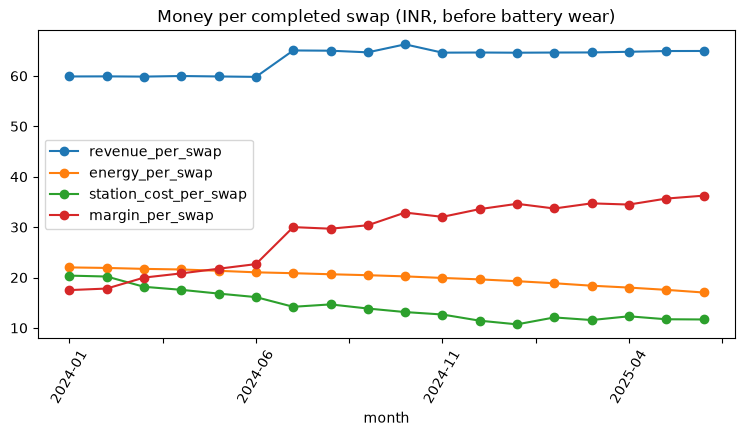

saved: 07_money_per_swap


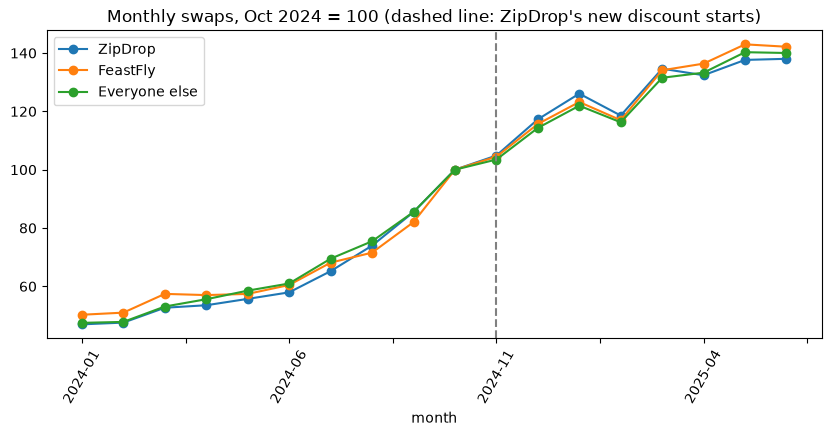

saved: 08_zipdrop_volume
['01_clock_bug_before_after.png', '02_network_trends.png', '03_failures_by_charger_generation.png', '04_failures_by_city.png', '05_heat_and_charging_time.png', '06_churn_by_failure_share.png', '07_money_per_swap.png', '08_zipdrop_volume.png']


In [84]:
os.makedirs("charts", exist_ok=True)

def save(name):
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("saved:", name)

# 1. Clock bug, before and after the fix
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax[0].plot(hours_ok.index, hours_ok.values * 100, label="Normal stations", lw=2)
ax[0].plot(hours_bug.index, hours_bug.values * 100, "--", label="v3.2.0 stations (as logged)", lw=2)
ax[0].set_title("Before fix: bug stations log times 5.5 hours early")
ax[1].plot(hours_normal.index, hours_normal.values * 100, label="Normal stations", lw=2)
ax[1].plot(hours_fixed.index, hours_fixed.values * 100, "--", label="v3.2.0 stations (fixed)", lw=2)
ax[1].set_title("After fix: both follow the same daily pattern")
for a in ax:
    a.set_xlabel("Hour of day"); a.legend(); a.set_xticks(range(0, 24, 2))
ax[0].set_ylabel("% of swaps")
save("01_clock_bug_before_after")

# 2. Network trends
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
monthly["completed_swaps"].plot(ax=ax[0], marker="o")
ax[0].set_title("Completed swaps per month")
monthly["failure_rate_pct"].plot(ax=ax[1], marker="o", color="tab:red")
ax[1].set_title("Service failure rate (% of attempts)")
for a in ax: a.tick_params(axis="x", rotation=60)
plt.tight_layout()
save("02_network_trends")

# 3. Failures by charger generation
gen.plot(marker="o", figsize=(10, 4))
plt.title("Service failure rate by charger generation")
plt.ylabel("% of attempts that failed"); plt.xticks(rotation=60)
save("03_failures_by_charger_generation")

# 4. Failures by city
city.plot(marker="o", figsize=(10, 4))
plt.title("Service failure rate by city")
plt.ylabel("% of attempts that failed"); plt.xticks(rotation=60)
save("04_failures_by_city")

# 5. Heat and charging time (Gen1 stations)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
temp.plot(ax=ax[0], marker="o"); ax[0].set_title("Cabinet temperature (°C), Gen1 stations")
charge.plot(ax=ax[1], marker="o"); ax[1].set_title("Minutes to charge a pack, Gen1 stations")
for a in ax: a.tick_params(axis="x", rotation=60)
plt.tight_layout()
save("05_heat_and_charging_time")

# 6. Churn by failure share
core = new[new["attempts_30d"] >= 11].copy()
core["fail_band"] = pd.cut(core["fail_rate_30d"], [0, 0.05, 0.10, 0.25, 1.0],
                           labels=["up to 5%", "5-10%", "10-25%", "over 25%"])
tb = core.groupby("fail_band", observed=True).agg(riders=("churned", "size"), churn_pct=("churned", "mean"))
tb["churn_pct"] = (tb["churn_pct"] * 100).round(1)
ax = tb["churn_pct"].plot(kind="bar", figsize=(7, 4), color="tab:red")
for i, (v_, n_) in enumerate(zip(tb["churn_pct"], tb["riders"])):
    ax.text(i, v_ + 0.8, f"{v_}%\n(n={n_})", ha="center")
plt.title("New riders who did not return, by share of attempts that failed")
plt.xlabel("Share of first-30-day attempts that failed"); plt.ylabel("% who did not return")
plt.xticks(rotation=0); plt.ylim(0, tb["churn_pct"].max() + 10)
save("06_churn_by_failure_share")

# 7. Money per swap
money[["revenue_per_swap", "energy_per_swap", "station_cost_per_swap", "margin_per_swap"]].plot(marker="o", figsize=(9, 4))
plt.title("Money per completed swap (INR, before battery wear)")
plt.xticks(rotation=60)
save("07_money_per_swap")

# 8. ZipDrop volume after the bigger discount
ax = indexed.plot(marker="o", figsize=(10, 4))
ax.axvline(list(view.index).index("2024-11"), color="gray", linestyle="--")
plt.title("Monthly swaps, Oct 2024 = 100 (dashed line: ZipDrop's new discount starts)")
plt.xticks(rotation=60)
save("08_zipdrop_volume")

print(sorted(os.listdir("charts")))

In [85]:
c = comp[["city", "month", "event_ts", "tariff_code", "list_price_inr", "discount_inr", "amount_charged_inr"]].copy()
c["tariff"] = c["tariff_code"].astype(str)
c["hour"] = c["event_ts"].dt.hour
c["pilot_tariff"] = c["tariff"].isin(["PEAK", "OFFPEAK"])

print("Share of swaps by price type, per city (%):")
mix = c.groupby(["city", "tariff"], observed=True).size().unstack(fill_value=0)
print((mix.div(mix.sum(axis=1), axis=0) * 100).round(1))

print()
print("First and last pilot-priced swap, per city:")
print(c[c["pilot_tariff"]].groupby("city", observed=True)["event_ts"].agg(["min", "max", "size"]))

print()
print("Share of swaps on PEAK or OFFPEAK pricing, by month (%):")
print((c.groupby(["month", "city"], observed=True)["pilot_tariff"].mean().unstack() * 100).round(1))

Share of swaps by price type, per city (%):
tariff     OFFPEAK  PARTNER  PEAK   STD
city                                   
Bengaluru      2.8     67.0  12.9  17.3
Delhi NCR      0.0     66.0   0.0  34.0
Hyderabad      0.0     65.0   0.0  35.0
Jaipur         0.0     64.5   0.0  35.5
Mumbai         0.0     66.9   0.0  33.1
Pune           2.8     66.5  13.3  17.4

First and last pilot-priced swap, per city:
                          min                 max    size
city                                                     
Bengaluru 2024-10-01 00:05:41 2025-06-30 23:57:40  114331
Pune      2024-10-01 00:03:04 2025-06-30 23:40:57   84424

Share of swaps on PEAK or OFFPEAK pricing, by month (%):
city     Bengaluru  Delhi NCR  Hyderabad  Jaipur  Mumbai  Pune
month                                                         
2024-01        0.0        0.0        0.0     0.0     0.0   0.0
2024-02        0.0        0.0        0.0     0.0     0.0   0.0
2024-03        0.0        0.0        0.0     0.0 

In [86]:
print("Number of pilot swaps by hour of day:")
print(c[c["pilot_tariff"]].groupby(["hour", "tariff"]).size().unstack(fill_value=0))

print()
print("Average price per swap by price type (INR):")
print(c.groupby("tariff")[["list_price_inr", "discount_inr", "amount_charged_inr"]].mean().round(1))

Number of pilot swaps by hour of day:
tariff  OFFPEAK   PEAK
hour                  
0          1939      0
1          1907      0
2          2004      0
3          1989      0
4          3356      0
5          3267      0
12            0  28189
13            0  28266
14         4825      0
15         6224      0
16         6127      0
18            2      0
19            4  37505
20            4  37247
21            2  27856
22            4   4859
23         3179      0

Average price per swap by price type (INR):
         list_price_inr  discount_inr  amount_charged_inr
tariff                                                   
OFFPEAK            67.5           0.0                59.5
PARTNER            69.7           8.8                61.7
PEAK               67.5           0.0                82.5
STD                66.2           0.0                66.2


In [87]:
PEAK_H = [12, 13, 19, 20, 21, 22]
OFF_H = [0, 1, 2, 3, 4, 5, 14, 15, 16, 23]
BEFORE, AFTER = "Before (Jul-Sep 2024)", "After (Oct 2024-Mar 2025)"

d = comp[["event_id", "city", "month", "event_ts", "partner_str", "list_price_inr",
          "amount_charged_inr", "margin_pre_wear"]].copy()
d["hour"] = d["event_ts"].dt.hour
d["in_peak_hours"] = d["hour"].isin(PEAK_H)
d["in_off_hours"] = d["hour"].isin(OFF_H)
d["group"] = np.where(d["city"].astype(str).isin(["Bengaluru", "Pune"]), "Pilot cities", "Other cities")
d["rider_type"] = np.where(d["partner_str"] == "Independent", "Independent", "Fleet")
d["window"] = np.select([d["month"].between("2024-07", "2024-09"),
                         d["month"].between("2024-10", "2025-03")], [BEFORE, AFTER], default="other")
d = d[d["window"] != "other"]
print("Swaps compared:", len(d))
print()

def did_table(metric, scale=1):
    p = d.groupby(["rider_type", "group", "window"])[metric].mean().unstack("window") * scale
    p["change"] = p[AFTER] - p[BEFORE]
    return p[[BEFORE, AFTER, "change"]].round(1)

for metric, label, scale in [
    ("in_peak_hours", "% of swaps in peak hours (12-2 PM, 7-10 PM)", 100),
    ("in_off_hours", "% of swaps in off-peak hours", 100),
    ("amount_charged_inr", "average amount charged per swap (INR)", 1),
    ("margin_pre_wear", "average margin per swap before battery wear (INR)", 1)]:
    t = did_table(metric, scale)
    print(label)
    print(t)
    for rt in ["Independent", "Fleet"]:
        eff = t.loc[(rt, "Pilot cities"), "change"] - t.loc[(rt, "Other cities"), "change"]
        print(f"  -> {rt}: pilot cities changed {eff:+.1f} more than the other cities")
    print()

Swaps compared: 1989926

% of swaps in peak hours (12-2 PM, 7-10 PM)
window                    Before (Jul-Sep 2024)  After (Oct 2024-Mar 2025)  \
rider_type  group                                                            
Fleet       Other cities                   54.8                       55.8   
            Pilot cities                   57.2                       55.0   
Independent Other cities                   61.7                       61.7   
            Pilot cities                   61.9                       59.3   

window                    change  
rider_type  group                 
Fleet       Other cities     1.0  
            Pilot cities    -2.2  
Independent Other cities    -0.0  
            Pilot cities    -2.6  
  -> Independent: pilot cities changed -2.6 more than the other cities
  -> Fleet: pilot cities changed -3.2 more than the other cities

% of swaps in off-peak hours
window                    Before (Jul-Sep 2024)  After (Oct 2024-Mar 2025)  \
rider_ty

group    Other four cities  Pilot cities (Bengaluru, Pune)
month                                                     
2024-01               62.0                            62.3
2024-02               61.5                            61.8
2024-03               61.6                            61.4
2024-04               60.5                            61.7
2024-05               60.2                            61.3
2024-06               60.8                            61.4
2024-07               61.7                            62.6
2024-08               61.9                            61.7
2024-09               61.7                            61.5
2024-10               61.7                            59.3
2024-11               61.5                            59.2
2024-12               61.5                            59.2
2025-01               61.7                            59.2
2025-02               61.9                            59.4
2025-03               61.8                            59

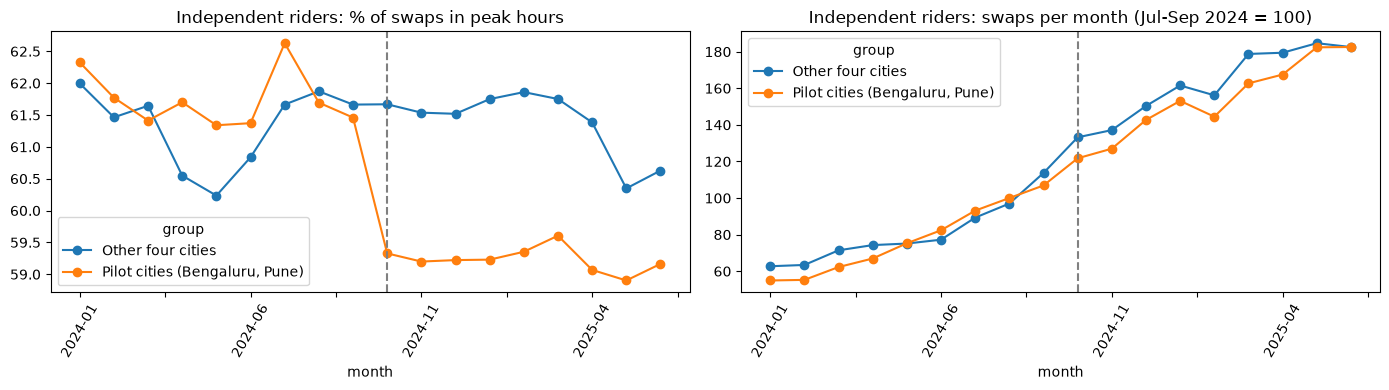

In [88]:
ind = comp[comp["partner_str"] == "Independent"][["city", "month", "event_ts"]].copy()
ind["peak"] = ind["event_ts"].dt.hour.isin(PEAK_H)
ind["group"] = np.where(ind["city"].astype(str).isin(["Bengaluru", "Pune"]), "Pilot cities (Bengaluru, Pune)", "Other four cities")

share = ind.groupby(["month", "group"])["peak"].mean().unstack() * 100
vol = ind.groupby(["month", "group"]).size().unstack()
vol_idx = vol / vol.loc["2024-07":"2024-09"].mean() * 100
print(share.round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
share.plot(ax=ax[0], marker="o")
ax[0].set_title("Independent riders: % of swaps in peak hours")
vol_idx.plot(ax=ax[1], marker="o")
ax[1].set_title("Independent riders: swaps per month (Jul-Sep 2024 = 100)")
pos = list(share.index).index("2024-10")
for a in ax:
    a.axvline(pos, color="gray", linestyle="--")
    a.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig("charts/09_pricing_pilot.png", dpi=150, bbox_inches="tight")
plt.show()

In [89]:
bill = partners.set_index("partner_id")["peak_surcharge_billable"]
f = comp[comp["partner_str"] != "Independent"][["city", "month", "event_ts", "partner_str", "list_price_inr", "amount_charged_inr"]].copy()
f = f[f["month"] >= "2024-10"]
f["billable"] = f["partner_str"].map(bill)
hr = f["event_ts"].dt.hour
f["hour_type"] = np.select([hr.isin(PEAK_H), hr.isin(OFF_H)], ["peak hours", "off-peak hours"], default="standard hours")
f["group"] = np.where(f["city"].astype(str).isin(["Bengaluru", "Pune"]), "Pilot cities", "Other cities")
f["price_ratio"] = f["amount_charged_inr"] / f["list_price_inr"]

r = f.groupby(["billable", "group", "hour_type"])["price_ratio"].mean().unstack().round(3)
print("Amount charged as a share of list price, fleet swaps from Oct 2024:")
print(r)

Amount charged as a share of list price, fleet swaps from Oct 2024:
hour_type              off-peak hours  peak hours  standard hours
billable group                                                   
N        Other cities           0.783       0.781           0.771
         Pilot cities           0.788       0.784           0.774
Y        Other cities           0.892       0.903           0.900
         Pilot cities           0.781       1.125           0.899


In [90]:
bill = partners.set_index("partner_id")["peak_surcharge_billable"]
d["segment"] = np.where(
    d["rider_type"] == "Independent", "Independent",
    np.where(d["partner_str"].map(bill) == "Y", "Fleet - billed", "Fleet - not billed"))

rows = []
for metric, label, scale in [
    ("in_peak_hours", "peak-hour share (pp)", 100),
    ("in_off_hours", "off-peak share (pp)", 100),
    ("amount_charged_inr", "avg charged (INR)", 1),
    ("margin_pre_wear", "margin pre-wear (INR)", 1)]:
    p = d.groupby(["segment", "group", "window"])[metric].mean().unstack("window") * scale
    for seg in d["segment"].unique():
        pc = p.loc[(seg, "Pilot cities"), AFTER] - p.loc[(seg, "Pilot cities"), BEFORE]
        oc = p.loc[(seg, "Other cities"), AFTER] - p.loc[(seg, "Other cities"), BEFORE]
        rows.append({"segment": seg, "metric": label,
                     "pilot_chg": pc, "other_chg": oc, "DiD": pc - oc})

print(pd.DataFrame(rows).round(2).to_string(index=False))
print()
print(d.groupby(["segment", "group"]).size().unstack())

           segment                metric  pilot_chg  other_chg   DiD
    Fleet - billed  peak-hour share (pp)      -2.92       1.42 -4.34
Fleet - not billed  peak-hour share (pp)      -0.80      -0.14 -0.66
       Independent  peak-hour share (pp)      -2.57      -0.04 -2.52
    Fleet - billed   off-peak share (pp)       1.88      -0.43  2.31
Fleet - not billed   off-peak share (pp)       0.59       0.11  0.47
       Independent   off-peak share (pp)       2.61       0.16  2.46
    Fleet - billed     avg charged (INR)       5.45      -0.71  6.17
Fleet - not billed     avg charged (INR)      -6.65      -6.83  0.18
       Independent     avg charged (INR)       7.89      -0.04  7.93
    Fleet - billed margin pre-wear (INR)       8.42       3.58  4.84
Fleet - not billed margin pre-wear (INR)      -3.37      -2.97 -0.40
       Independent margin pre-wear (INR)      11.02       3.74  7.27

group               Other cities  Pilot cities
segment                                       
Fleet - 

In [92]:
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and not name.startswith("_"):
        print(f"{name}: {obj.shape[0]:,} rows")
        print("   ", obj.columns.tolist())

stations: 150 rows
    ['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type', 'host_type', 'commissioned_date', 'decommissioned_date', 'expansion_wave', 'charger_generation', 'slots_2w', 'slots_3w', 'inventory_target_2w', 'inventory_target_3w', 'monthly_rent_inr', 'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier', 'firmware_version', 'firmware_updated_date', 'competitor_within_1_5km_since']
riders: 20,000 rows
    ['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city', 'city_clean']
batteries: 6,500 rows
    ['battery_id', 'pack_type', 'supplier', 'manufacturing_lot', 'manufacture_date', 'commission_date', 'rated_capacity_kwh', 'purchase_cost_inr', 'initial_soh_pct', 'bms_firmware', 'retired_date', 'retirement_reason', 'current_soh_pct']
tickets: 44,000 rows
    ['ticket_id', 'rider_id', 'station_id', 'battery_id', 'created_ts'

In [93]:
for name in ["stations", "swaps"]:
    print(f"--- {name} ---")
    for c in globals()[name].columns:
        print("  ", c)

print("--- other tables that look like hourly status / telemetry ---")
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and not name.startswith("_"):
        if any(k in name.lower() for k in ["hour", "status", "telem"]):
            print(name, f"{obj.shape[0]:,} rows")
            for c in obj.columns:
                print("  ", c)

print()
print(stations.head(3).T)

--- stations ---
   station_id
   city
   zone
   latitude
   longitude
   location_type
   host_type
   commissioned_date
   decommissioned_date
   expansion_wave
   charger_generation
   slots_2w
   slots_3w
   inventory_target_2w
   inventory_target_3w
   monthly_rent_inr
   monthly_maintenance_inr
   grid_tariff_inr_kwh
   connectivity_tier
   firmware_version
   firmware_updated_date
   competitor_within_1_5km_since
--- swaps ---
   event_id
   rider_id
   station_id
   event_ts
   event_type
   attempt_seq
   queue_wait_sec
   battery_in_id
   battery_out_id
   soc_in_pct
   soh_in_pct
   soc_out_pct
   soh_out_pct
   km_since_last_swap
   tariff_code
   list_price_inr
   discount_inr
   amount_charged_inr
   payment_mode
   energy_to_recharge_kwh
   station_firmware
   sync_mode
   ts_was_fixed
   km_invalid
   km_clean
   city
   zone
   location_type
   host_type
   expansion_wave
   charger_generation
   connectivity_tier
   commissioned_date
   grid_tariff_inr_kwh
   vehicle

In [94]:
import textwrap, os

print("SWAPS COLUMNS:")
print(textwrap.fill(", ".join(swaps.columns), 100))
print()
print("EVENT TYPES:")
print(swaps["event_type"].value_counts(dropna=False).to_string())
print()
print("CITY_CTX COLUMNS:")
print(textwrap.fill(", ".join(city_ctx.columns), 100))
print()
print("Hourly status table loaded?",
      [n for n, o in globals().items()
       if isinstance(o, pd.DataFrame) and "hour" in n.lower() and not n.startswith("_")])
try:
    print("Files in DATA_DIR:", os.listdir(DATA_DIR))
except Exception as e:
    print("DATA_DIR not readable:", e)

SWAPS COLUMNS:
event_id, rider_id, station_id, event_ts, event_type, attempt_seq, queue_wait_sec, battery_in_id,
battery_out_id, soc_in_pct, soh_in_pct, soc_out_pct, soh_out_pct, km_since_last_swap, tariff_code,
list_price_inr, discount_inr, amount_charged_inr, payment_mode, energy_to_recharge_kwh,
station_firmware, sync_mode, ts_was_fixed, km_invalid, km_clean, city, zone, location_type,
host_type, expansion_wave, charger_generation, connectivity_tier, commissioned_date,
grid_tariff_inr_kwh, vehicle_class, partner_id, plan_type, signup_channel, signup_date, rider_city,
month, completed, service_failure

EVENT TYPES:
event_type
swap_completed               3586675
failed_no_charged_battery     132786
abandoned_queue                67663
cancelled_by_rider             16458
failed_system_error            11400

CITY_CTX COLUMNS:
city, date, max_temp_c, min_temp_c, rainfall_mm, heat_alert, flood_disruption, festival_or_event,
is_public_holiday, grid_outage_hours, competitor_promo_active,

Check vs existing service_failure flag:
service_failure              False   True 
event_type                                
abandoned_queue                  0   67663
cancelled_by_rider           16458       0
failed_no_charged_battery        0  132786
failed_system_error              0   11400
swap_completed             3586675       0

Worst 10% of stations (15 of 150) = 24.7% of failures, 17.2% of attempts
Worst 15% of stations (22 of 150) = 33.5% of failures, 23.7% of attempts
Worst 20% of stations (30 of 150) = 42.7% of failures, 31.0% of attempts
Network failure rate: 5.55%



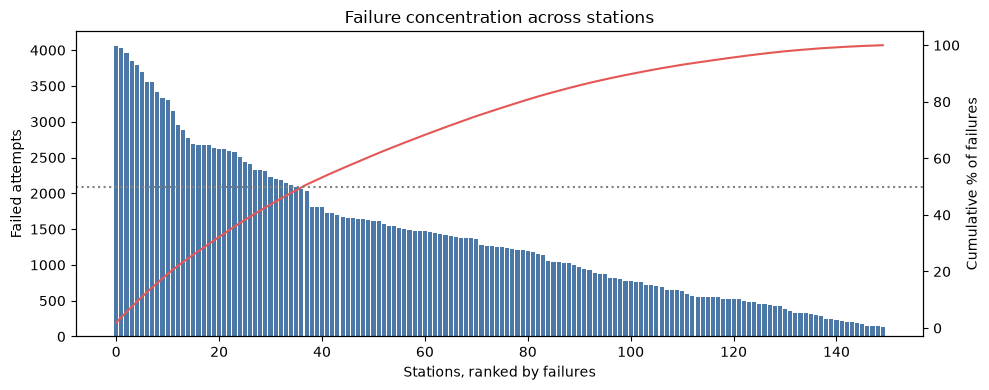

                    stations  attempts  fail_rate_%  tickets_per_1k_swaps
charger_generation                                                       
Gen1                      51   1822034         6.80                 12.68
Gen2                      62   1620707         4.42                  9.93
Gen3                      37    372241         4.40                 12.68

                   stations  attempts  fail_rate_%  tickets_per_1k_swaps
location_type                                                           
commercial_hub           44   1535743         5.75                 11.46
highway_fuel_pump        21    329834         4.69                 12.53
market                   47   1246931         5.80                 11.50
residential              21    382274         5.01                 11.42
tech_park                 7    147533         4.77                 10.07
transit_hub              10    172667         5.52                 11.22

                stations  attempts  fail_rat

In [95]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("charts", exist_ok=True)

FAIL = ["failed_no_charged_battery", "failed_system_error", "abandoned_queue"]
cols = ["station_id", "city", "event_ts", "event_type", "charger_generation",
        "location_type", "expansion_wave", "connectivity_tier", "queue_wait_sec", "service_failure"]
s = swaps[cols].copy()
s["fail"] = s["event_type"].isin(FAIL)
s["completed_flag"] = s["event_type"].eq("swap_completed")
for c in ["city", "charger_generation", "location_type", "expansion_wave", "connectivity_tier"]:
    s[c] = s[c].astype(str)

print("Check vs existing service_failure flag:")
print(pd.crosstab(s["event_type"], s["service_failure"]))
print()

# ---- 1. Pareto: station concentration ----
st = s.groupby("station_id").agg(attempts=("fail", "size"), failures=("fail", "sum"))
st["rate"] = st["failures"] / st["attempts"] * 100
st = st.sort_values("failures", ascending=False)
st["cum_share"] = st["failures"].cumsum() / st["failures"].sum() * 100
n = len(st)
for pct in [10, 15, 20]:
    k = int(round(n * pct / 100))
    print(f"Worst {pct}% of stations ({k} of {n}) = {st['cum_share'].iloc[k-1]:.1f}% of failures, "
          f"{st['attempts'].iloc[:k].sum() / st['attempts'].sum() * 100:.1f}% of attempts")
print(f"Network failure rate: {s['fail'].mean()*100:.2f}%")
print()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(n), st["failures"].values, color="#4c78a8")
ax2 = ax.twinx()
ax2.plot(range(n), st["cum_share"].values, color="#e45756")
ax2.axhline(50, color="gray", linestyle=":")
ax.set_xlabel("Stations, ranked by failures"); ax.set_ylabel("Failed attempts"); ax2.set_ylabel("Cumulative % of failures")
ax.set_title("Failure concentration across stations")
plt.tight_layout(); plt.savefig("charts/q3_pareto.png", dpi=150); plt.show()

# ---- 2. Failure rate by station attribute ----
tix = tickets.groupby("station_id").size().rename("tickets")
done = s[s["completed_flag"]].groupby("station_id").size().rename("completed")
sd = st.join(tix).join(done).fillna(0)
sd = sd.join(stations.set_index("station_id")[["charger_generation", "location_type", "expansion_wave", "city"]])

def by(attr):
    g = sd.groupby(attr).agg(stations=("attempts", "size"), attempts=("attempts", "sum"),
                             failures=("failures", "sum"), tickets=("tickets", "sum"),
                             completed=("completed", "sum"))
    g["fail_rate_%"] = g["failures"] / g["attempts"] * 100
    g["tickets_per_1k_swaps"] = g["tickets"] / g["completed"] * 1000
    return g[["stations", "attempts", "fail_rate_%", "tickets_per_1k_swaps"]].round(2)

for a in ["charger_generation", "location_type", "expansion_wave"]:
    print(by(a)); print()

print("Gen mix by city (stations):")
print(pd.crosstab(sd["city"], sd["charger_generation"])); print()

# ---- 3. Heat x charger generation ----
ctx = city_ctx[["city", "date", "max_temp_c"]].copy()
ctx["city"] = ctx["city"].astype(str)
ctx["date"] = pd.to_datetime(ctx["date"]).dt.normalize()
s["date"] = s["event_ts"].dt.normalize()
m = s.merge(ctx, on=["city", "date"], how="left")
m["heat"] = pd.cut(m["max_temp_c"], [-np.inf, 30, 35, 40, np.inf],
                   labels=["<30C", "30-35C", "35-40C", "40C+"])
hp = m.groupby(["charger_generation", "heat"], observed=True)["fail"].agg(["mean", "size"])
print("Failure rate % by charger generation x daily max temperature:")
print((hp["mean"].unstack() * 100).round(2))
print("Attempts:")
print(hp["size"].unstack())
print()

# ---- 4. Hourly table: just inspect it ----
print("HOURLY columns:", hourly.columns.tolist())
print(hourly.head(3).T)

In [96]:
import textwrap

print("Stations: wave x generation")
print(pd.crosstab(sd["expansion_wave"], sd["charger_generation"]))
print()
print("Stations: city x generation")
print(pd.crosstab(sd["city"], sd["charger_generation"]))
print()

for key in ["expansion_wave", "city"]:
    g = sd.groupby([key, "charger_generation"]).agg(a=("attempts", "sum"), f=("failures", "sum"))
    print(f"Failure rate % by {key} x generation:")
    print((g["f"] / g["a"] * 100).unstack().round(2))
    print()

print("Failure rate % by generation x daily max temp:")
print((hp["mean"].unstack() * 100).round(2))
print("Attempts:")
print(hp["size"].unstack())
print()

print("HOURLY columns:")
print(textwrap.fill(", ".join(hourly.columns), 100))

Stations: wave x generation
charger_generation  Gen1  Gen2  Gen3
expansion_wave                      
Launch                51    39     0
Wave1_2024H2           0    23     7
Wave2_2025H1           0     0    30

Stations: city x generation
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru              9    16     7
Delhi NCR             13    10     7
Hyderabad             13     6     7
Jaipur                10     3     5
Mumbai                 2    15     5
Pune                   4    12     6

Failure rate % by expansion_wave x generation:
charger_generation  Gen1  Gen2  Gen3
expansion_wave                      
Launch               6.8  4.38   NaN
Wave1_2024H2         NaN  4.55  4.13
Wave2_2025H1         NaN   NaN  4.54

Failure rate % by city x generation:
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru           4.23  4.02  4.08
Delhi NCR           8.09  5.34  4.80
Hyderabad           7.02  4.94  4.32
Jaipur

In [97]:
import numpy as np, pandas as pd

# 1. City x generation failure rate (was cut off)
g = sd.groupby(["city", "charger_generation"], observed=True).agg(a=("attempts", "sum"), f=("failures", "sum"))
print("Failure rate % by city x generation:")
print((g["f"] / g["a"] * 100).unstack().round(2))
print()

# 2. Heat x generation, all stations vs Launch wave only
print("Failure rate % by generation x daily max temp (all):")
print((hp["mean"].unstack() * 100).round(2))
print("Attempts:"); print(hp["size"].unstack()); print()

L = m[m["expansion_wave"].astype(str) == "Launch"]
hl = L.groupby(["charger_generation", "heat"], observed=True)["fail"].agg(["mean", "size"])
print("Launch wave only (Gen1 vs Gen2):")
print((hl["mean"].unstack() * 100).round(2))
print("Attempts:"); print(hl["size"].unstack()); print()

# 3. Stockout check from hourly (telemetry_ok rows only)
h = hourly[hourly["telemetry_ok"].astype(bool)].copy()
h["station_id"] = h["station_id"].astype(str)
h["charger_generation"] = h["charger_generation"].astype(str)
h["stockout_2w"] = h["charged_2w_min"] == 0
h["stockout_3w"] = h["charged_3w_min"] == 0
h["stockout"] = h["stockout_2w"] | h["stockout_3w"]
print(f"Telemetry-ok hours: {len(h):,} of {len(hourly):,}")

bg = h.groupby("charger_generation").agg(
    stockout_hours_pct=("stockout", "mean"),
    stockout_2w_pct=("stockout_2w", "mean"),
    stockout_3w_pct=("stockout_3w", "mean"),
    cabinet_temp_c=("cabinet_temp_c", "mean"),
    avg_charge_min=("avg_charge_minutes", "mean"),
    chargers_online=("chargers_online", "mean"),
    outage_min=("outage_minutes", "mean"))
for c in ["stockout_hours_pct", "stockout_2w_pct", "stockout_3w_pct"]:
    bg[c] *= 100
print("\nHourly status by charger generation:")
print(bg.round(2)); print()

# 4. Do stockouts line up with failures at station level?
so = h.groupby("station_id")["stockout"].mean() * 100
sd2 = sd.copy()
sd2.index = sd2.index.astype(str)
sd2 = sd2.join(so.rename("stockout_pct"))
sd2["fail_rate"] = sd2["failures"] / sd2["attempts"] * 100
print("Station-level correlation, failure rate vs stockout-hours %:",
      round(sd2[["fail_rate", "stockout_pct"]].corr().iloc[0, 1], 2))
print(sd2.groupby("charger_generation", observed=True)[["fail_rate", "stockout_pct"]].mean().round(2))

Failure rate % by city x generation:
charger_generation  Gen1  Gen2  Gen3
city                                
Bengaluru           4.23  4.02  4.08
Delhi NCR           8.09  5.34  4.80
Hyderabad           7.02  4.94  4.32
Jaipur              8.14  5.28  4.76
Mumbai              4.07  4.00  3.97
Pune                5.16  4.42  4.12

Failure rate % by generation x daily max temp (all):
heat                <30C  30-35C  35-40C   40C+
charger_generation                             
Gen1                3.89    4.02   14.16  19.01
Gen2                3.95    3.99    7.10   9.43
Gen3                3.87    3.96    4.86   5.49
Attempts:
heat                   <30C  30-35C  35-40C    40C+
charger_generation                                 
Gen1                1234341  161669  239110  186914
Gen2                1151371  273313  137878   58145
Gen3                 146202   73089   90172   62778

Launch wave only (Gen1 vs Gen2):
heat                <30C  30-35C  35-40C   40C+
charger_generation   

In [98]:
h["amb"] = pd.cut(h["ambient_temp_c"], [-np.inf, 30, 35, 40, np.inf],
                  labels=["<30C", "30-35C", "35-40C", "40C+"])

for col, label, scale in [("stockout", "Stockout-hours %", 100),
                          ("avg_charge_minutes", "Avg charge minutes", 1),
                          ("cabinet_temp_c", "Cabinet temp (C)", 1)]:
    t = h.groupby(["charger_generation", "amb"], observed=True)[col].mean().unstack() * scale
    print(label, "by generation x ambient temp:")
    print(t.round(2)); print()

print("Hourly status by generation:")
print(bg.round(2).to_string()); print()
print("Station-level corr, failure rate vs stockout %:",
      round(sd2[["fail_rate", "stockout_pct"]].corr().iloc[0, 1], 2)); print()
print("Launch wave only, failure rate % by gen x heat:")
print((hl["mean"].unstack() * 100).round(2).to_string())

Stockout-hours % by generation x ambient temp:
amb                 <30C  30-35C  35-40C   40C+
charger_generation                             
Gen1                0.70    2.74   16.03  69.18
Gen2                0.37    0.51    0.77   1.06
Gen3                0.25    0.35    0.27   0.38

Avg charge minutes by generation x ambient temp:
amb                  <30C  30-35C  35-40C    40C+
charger_generation                               
Gen1                87.99   91.27  118.62  174.37
Gen2                63.99   64.56   68.35   74.18
Gen3                42.01   42.10   42.77   43.78

Cabinet temp (C) by generation x ambient temp:
amb                  <30C  30-35C  35-40C   40C+
charger_generation                              
Gen1                22.02   39.79   44.72  50.63
Gen2                22.78   39.66   44.53  50.60
Gen3                23.95   39.78   44.66  50.69

Hourly status by generation:
                    stockout_hours_pct  stockout_2w_pct  stockout_3w_pct  cabinet_temp_c  

In [99]:
import textwrap
print("RIDERS:", textwrap.fill(", ".join(riders.columns), 100)); print()
print("TICKETS:", textwrap.fill(", ".join(tickets.columns), 100)); print()
print(riders["signup_channel"].value_counts().to_string()); print()
print(riders["plan_type"].value_counts().to_string()); print()
print("signup range:", riders["signup_date"].min(), "to", riders["signup_date"].max())
print("rider ids in swaps:", swaps["rider_id"].nunique(), "of", len(riders))

RIDERS: rider_id, partner_id, vehicle_class, vehicle_model, home_zone, signup_date, signup_channel,
plan_type, declared_shift, age_band, kyc_verified, home_city, city_clean

TICKETS: ticket_id, rider_id, station_id, battery_id, created_ts, channel, category, rider_comment, priority,
resolution_status, resolution_hours, csat_score

signup_channel
partner_onboarding    9376
app_store             4215
field_agent           4144
referral              2265

plan_type
partner_billed    12372
pay_as_you_go      5299
prepaid_pack       2329

signup range: 2023-03-08 00:00:00 to 2025-06-30 00:00:00
rider ids in swaps: 19941 of 20000


In [100]:
import numpy as np, pandas as pd

r = riders[["rider_id", "signup_channel", "plan_type", "vehicle_class", "city_clean", "signup_date"]].copy()
r["rider_id"] = r["rider_id"].astype(str)

s2 = swaps[["rider_id", "event_ts", "event_type", "queue_wait_sec", "station_id"]].copy()
s2["rider_id"] = s2["rider_id"].astype(str)
s2["done"] = s2["event_type"].eq("swap_completed")
s2["fail"] = s2["event_type"].isin(["failed_no_charged_battery", "failed_system_error", "abandoned_queue"])

first = s2[s2["done"]].groupby("rider_id")["event_ts"].min().rename("first_swap")
s2 = s2.join(first, on="rider_id").dropna(subset=["first_swap"])
s2["day"] = (s2["event_ts"] - s2["first_swap"]).dt.total_seconds() / 86400

wk1 = s2[(s2["day"] >= 0) & (s2["day"] < 7)].groupby("rider_id").agg(
    wk1_attempts=("done", "size"), wk1_fails=("fail", "sum"),
    wk1_wait_min=("queue_wait_sec", lambda x: x.mean() / 60))
wk1["wk1_failed"] = (wk1["wk1_fails"] > 0).astype(int)

ret = s2[s2["done"] & (s2["day"] >= 7) & (s2["day"] < 37)].groupby("rider_id").size().rename("returns")

t = tickets.copy()
t["rider_id"] = t["rider_id"].astype(str)
t = t.join(first, on="rider_id").dropna(subset=["first_swap"])
t["day"] = (pd.to_datetime(t["created_ts"]) - t["first_swap"]).dt.total_seconds() / 86400
wk1_t = t[(t["day"] >= 0) & (t["day"] < 7)].groupby("rider_id").size().rename("wk1_tickets")

d = r.join(first, on="rider_id").dropna(subset=["first_swap"]).set_index("rider_id")
d = d.join(wk1).join(ret).join(wk1_t)
for c in ["wk1_attempts", "wk1_fails", "wk1_failed", "returns", "wk1_tickets"]:
    d[c] = d[c].fillna(0)
d["wk1_wait_min"] = d["wk1_wait_min"].fillna(d["wk1_wait_min"].median())

# only riders with a full 37-day window before data ends (30 Jun 2025)
d = d[d["first_swap"] <= pd.Timestamp("2025-06-30") - pd.Timedelta(days=37)]
d["not_returned"] = (d["returns"] == 0).astype(int)
d["cohort"] = d["first_swap"].dt.to_period("M").astype(str)
print(f"Riders analysed: {len(d):,}   Overall non-return rate: {d['not_returned'].mean()*100:.1f}%\n")

def tab(col):
    g = d.groupby(col, observed=True)["not_returned"].agg(["mean", "size"])
    g["mean"] = (g["mean"] * 100).round(1)
    return g.rename(columns={"mean": "non_return_%", "size": "riders"})

print("By week-1 failed attempts (0 vs 1 vs 2+):")
print(tab(pd.cut(d["wk1_fails"], [-1, 0, 1, 99], labels=["0", "1", "2+"])), "\n")
print("By week-1 tickets (0 vs 1+):"); print(tab(d["wk1_tickets"].clip(upper=1)), "\n")
print("By week-1 avg wait:"); print(tab(pd.qcut(d["wk1_wait_min"], 4, duplicates="drop")), "\n")
for c in ["signup_channel", "plan_type", "vehicle_class", "city_clean"]:
    print(f"By {c}:"); print(tab(c), "\n")
print("By signup cohort:"); print(tab("cohort"))

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
X = pd.get_dummies(d[["signup_channel", "plan_type", "vehicle_class"]], drop_first=True).astype(float)
for c in ["wk1_fails", "wk1_wait_min", "wk1_tickets"]:
    X[c] = d[c]
Xs = StandardScaler().fit_transform(X)
lr = LogisticRegression(max_iter=1000).fit(Xs, d["not_returned"])
print("\nDriver ranking (standardised logistic coefficients, bigger = stronger):")
print(pd.Series(lr.coef_[0], index=X.columns).sort_values(key=abs, ascending=False).round(2).head(10))

Riders analysed: 18,340   Overall non-return rate: 3.0%

By week-1 failed attempts (0 vs 1 vs 2+):
           non_return_%  riders
wk1_fails                      
0                   3.0   13462
1                   2.4    3944
2+                  5.1     934 

By week-1 tickets (0 vs 1+):
             non_return_%  riders
wk1_tickets                      
0.0                   3.0   17142
1.0                   2.9    1198 

By week-1 avg wait:
                            non_return_%  riders
wk1_wait_min                                    
(1.0490000000000002, 3.33]           4.1    4589
(3.33, 3.908]                        2.1    4591
(3.908, 4.594]                       2.2    4575
(4.594, 18.9]                        3.7    4585 

By signup_channel:
                    non_return_%  riders
signup_channel                          
app_store                    2.6    3887
field_agent                  3.7    3804
partner_onboarding           3.0    8567
referral                     2.6

In [101]:
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

FAIL = ["failed_no_charged_battery", "failed_system_error", "abandoned_queue"]

r = riders[["rider_id", "signup_channel", "plan_type", "vehicle_class", "city_clean", "signup_date"]].copy()
r["rider_id"] = r["rider_id"].astype(str)
r = r[r["signup_date"] >= pd.Timestamp("2024-01-01")]          # new riders only

e = swaps[["rider_id", "event_ts", "event_type", "queue_wait_sec"]].copy()
e["rider_id"] = e["rider_id"].astype(str)
e["done"] = e["event_type"].eq("swap_completed")
e["fail"] = e["event_type"].isin(FAIL)
first = e.groupby("rider_id")["event_ts"].min().rename("first_event")   # first attempt of ANY type
e = e.join(first, on="rider_id")
e["day"] = (e["event_ts"] - e["first_event"]).dt.total_seconds() / 86400

wk1 = e[e["day"] < 7].groupby("rider_id").agg(
    wk1_attempts=("done", "size"), wk1_fails=("fail", "sum"),
    wk1_wait_min=("queue_wait_sec", lambda x: x.mean() / 60))
ret = e[e["done"] & (e["day"] >= 7) & (e["day"] < 37)].groupby("rider_id").size().rename("returns")

t = tickets.copy()
t["rider_id"] = t["rider_id"].astype(str)
t = t.join(first, on="rider_id").dropna(subset=["first_event"])
t["day"] = (pd.to_datetime(t["created_ts"]) - t["first_event"]).dt.total_seconds() / 86400
wk1_t = t[t["day"] < 7].groupby("rider_id").size().rename("wk1_tickets")

d = r.join(first, on="rider_id").dropna(subset=["first_event"]).set_index("rider_id")
d = d.join(wk1).join(ret).join(wk1_t)
for c in ["returns", "wk1_tickets"]:
    d[c] = d[c].fillna(0)
d["wk1_wait_min"] = d["wk1_wait_min"].fillna(d["wk1_wait_min"].median())
d = d[d["first_event"] <= pd.Timestamp("2025-06-30") - pd.Timedelta(days=37)]

gap = (d["first_event"] - d["signup_date"]).dt.days
print(f"New riders analysed: {len(d):,}   (median days signup -> first attempt: {gap.median():.0f})")
print("Completed swaps in days 7-37, quantiles:")
print(d["returns"].quantile([.05, .1, .25, .5, .75]).to_string(), "\n")

d["no_return"] = (d["returns"] == 0).astype(int)
d["low_use"] = (d["returns"] <= 3).astype(int)
d["cohort"] = d["first_event"].dt.to_period("M").astype(str)
print(f"No-return rate: {d['no_return'].mean()*100:.1f}%   Low-use (<=3 swaps) rate: {d['low_use'].mean()*100:.1f}%\n")

def tab(col, y):
    g = d.groupby(col, observed=True)[y].agg(["mean", "size"])
    g["mean"] = (g["mean"] * 100).round(1)
    return g.rename(columns={"mean": f"{y}_%", "size": "riders"})

for y in ["no_return", "low_use"]:
    print(f"===== {y} =====")
    print(tab(pd.cut(d["wk1_fails"], [-1, 0, 1, 2, 99], labels=["0", "1", "2", "3+"]), y), "\n")
    print(tab(pd.qcut(d["wk1_wait_min"], 4, duplicates="drop"), y), "\n")
    for c in ["plan_type", "signup_channel", "vehicle_class"]:
        print(tab(c, y), "\n")

X = pd.get_dummies(d[["signup_channel", "plan_type", "vehicle_class"]], drop_first=True).astype(float)
for c in ["wk1_fails", "wk1_wait_min", "wk1_tickets"]:
    X[c] = d[c]
lr = LogisticRegression(max_iter=1000).fit(StandardScaler().fit_transform(X), d["low_use"])
print("Driver ranking for low_use (standardised coefficients):")
print(pd.Series(lr.coef_[0], index=X.columns).sort_values(key=abs, ascending=False).round(2).head(8))

New riders analysed: 14,747   (median days signup -> first attempt: 0)
Completed swaps in days 7-37, quantiles:
0.05     3.0
0.10    10.0
0.25    21.0
0.50    26.0
0.75    32.0 

No-return rate: 3.3%   Low-use (<=3 swaps) rate: 5.7%

===== no_return =====
           no_return_%  riders
wk1_fails                     
0                  3.4   10183
1                  2.5    3530
2                  5.2     808
3+                 8.0     226 

                 no_return_%  riders
wk1_wait_min                        
(0.0157, 3.322]          4.7    3693
(3.322, 3.904]           2.3    3681
(3.904, 4.589]           2.3    3692
(4.589, 18.9]            4.1    3681 

                no_return_%  riders
plan_type                          
partner_billed          3.5    9059
pay_as_you_go           3.0    3963
prepaid_pack            3.5    1725 

                    no_return_%  riders
signup_channel                         
app_store                   2.8    3125
field_agent                 4.

In [102]:
ind = d[d["plan_type"] != "partner_billed"].copy()
print(f"Independent new riders: {len(ind):,}")
print(f"No-return: {ind['no_return'].mean()*100:.1f}%   Low-use: {ind['low_use'].mean()*100:.1f}%\n")

# main station in week 1 -> competitor exposure
sw = swaps[["rider_id", "station_id", "event_ts"]].copy()
sw["rider_id"] = sw["rider_id"].astype(str)
sw["station_id"] = sw["station_id"].astype(str)
sw = sw.join(first, on="rider_id")
sw = sw[(sw["event_ts"] - sw["first_event"]).dt.total_seconds() < 7 * 86400]
home = sw.groupby(["rider_id", "station_id"]).size().reset_index(name="n")
home = home.sort_values("n", ascending=False).drop_duplicates("rider_id").set_index("rider_id")["station_id"]
comp_since = stations.assign(station_id=stations["station_id"].astype(str)).set_index("station_id")["competitor_within_1_5km_since"]

ind["home_stn"] = home.reindex(ind.index)
ind["comp_since"] = pd.to_datetime(ind["home_stn"].map(comp_since))
ind["comp_before"] = (ind["comp_since"] <= ind["first_event"]).astype(int)
ind["comp_in_window"] = ((ind["comp_since"] > ind["first_event"] + pd.Timedelta(days=7)) &
                         (ind["comp_since"] <= ind["first_event"] + pd.Timedelta(days=37))).astype(int)

def tab2(col, y):
    g = ind.groupby(col, observed=True)[y].agg(["mean", "size"])

Independent new riders: 5,688
No-return: 3.1%   Low-use: 5.3%



In [103]:
end = pd.Timestamp("2025-06-30")
last = e[e["done"]].groupby("rider_id")["event_ts"].max().rename("last_swap")

d2 = d.join(last)
d2["lapsed"] = (d2["last_swap"] < end - pd.Timedelta(days=45)).astype(int)
d2["tenure_d"] = (d2["last_swap"] - d2["first_event"]).dt.days
d2 = d2[d2["first_event"] <= pd.Timestamp("2025-03-15")]
print(f"Riders analysed: {len(d2):,}   Lapsed rate: {d2['lapsed'].mean()*100:.1f}%")
print("Tenure (days first->last swap) quantiles:"); print(d2["tenure_d"].quantile([.05,.1,.25,.5]).to_string(), "\n")

def tabL(df, col):
    g = df.groupby(col, observed=True)["lapsed"].agg(["mean", "size"])
    g["mean"] = (g["mean"] * 100).round(1)
    return g.rename(columns={"mean": "lapsed_%", "size": "riders"})

print("By week-1 failures:"); print(tabL(d2, pd.cut(d2["wk1_fails"], [-1,0,1,2,99], labels=["0","1","2","3+"])), "\n")
for c in ["plan_type", "signup_channel", "vehicle_class", "city_clean", "cohort"]:
    print(f"By {c}:"); print(tabL(d2, c), "\n")

if "comp_before" in ind:
    i2 = ind.join(last).copy()
    i2["lapsed"] = (i2["last_swap"] < end - pd.Timedelta(days=45)).astype(int)
    i2 = i2[i2["first_event"] <= pd.Timestamp("2025-03-15")]
    for c in ["comp_before", "comp_in_window"]:
        print(f"Independents, by {c}:"); print(tabL(i2, c), "\n")

Riders analysed: 12,152   Lapsed rate: 40.2%
Tenure (days first->last swap) quantiles:
0.05     15.0
0.10     34.9
0.25    116.0
0.50    193.0 

By week-1 failures:
           lapsed_%  riders
wk1_fails                  
0              39.1    8631
1              41.0    2808
2              48.2     568
3+             57.2     145 

By plan_type:
                lapsed_%  riders
plan_type                       
partner_billed      40.6    7435
pay_as_you_go       40.1    3289
prepaid_pack        38.3    1428 

By signup_channel:
                    lapsed_%  riders
signup_channel                      
app_store               39.7    2592
field_agent             39.0    2507
partner_onboarding      41.0    5633
referral                39.9    1420 

By vehicle_class:
               lapsed_%  riders
vehicle_class                  
2W                 40.0   10402
3W                 41.5    1750 

By city_clean:
            lapsed_%  riders
city_clean                  
Bengaluru       39.8

In [104]:
d2["lapse_month"] = d2["last_swap"].dt.to_period("M").astype(str)
for c in ["signup_channel", "vehicle_class", "city_clean", "cohort"]:
    print(f"By {c}:"); print(tabL(d2, c).to_string(), "\n")

print("Lapsed riders: month of last swap")
print(d2[d2["lapsed"] == 1]["lapse_month"].value_counts().sort_index().to_string(), "\n")

X = pd.get_dummies(d2[["signup_channel", "plan_type", "vehicle_class", "city_clean"]], drop_first=True).astype(float)
for c in ["wk1_fails", "wk1_tickets"]:
    X[c] = d2[c]
lr = LogisticRegression(max_iter=1000).fit(StandardScaler().fit_transform(X), d2["lapsed"])
print("Driver ranking for lapsed (standardised):")
print(pd.Series(lr.coef_[0], index=X.columns).sort_values(key=abs, ascending=False).round(2).head(8).to_string())

By signup_channel:
                    lapsed_%  riders
signup_channel                      
app_store               39.7    2592
field_agent             39.0    2507
partner_onboarding      41.0    5633
referral                39.9    1420 

By vehicle_class:
               lapsed_%  riders
vehicle_class                  
2W                 40.0   10402
3W                 41.5    1750 

By city_clean:
            lapsed_%  riders
city_clean                  
Bengaluru       39.8    2699
Delhi NCR       41.8    2382
Hyderabad       38.9    2092
Jaipur          42.9    1517
Mumbai          38.0    1719
Pune            39.9    1743 

By cohort:
         lapsed_%  riders
cohort                   
2024-01      58.5     583
2024-02      63.0     567
2024-03      54.5     600
2024-04      54.8     660
2024-05      60.8     717
2024-06      49.4     717
2024-07      45.5     804
2024-08      42.9     856
2024-09      39.0     869
2024-10      37.1    1187
2024-11      31.9    1019
2024-12    

In [106]:
stn = stations.assign(station_id=stations["station_id"].astype(str)).set_index("station_id")
d2["home_stn"] = home.reindex(d2.index)
d2["home_gen"] = d2["home_stn"].map(stn["charger_generation"].astype(str))
d2["comp_since"] = pd.to_datetime(d2["home_stn"].map(comp_since))
d2["comp_status"] = np.select(
    [d2["comp_since"].isna(), d2["comp_since"] <= d2["first_event"]],
    ["no competitor", "competitor before 1st swap"], default="competitor opened later")

f30 = e[e["day"] < 30].groupby("rider_id")["fail"].mean().rename("f30")
d2 = d2.drop(columns=["f30"], errors="ignore").join(f30)
d2["f30"] = d2["f30"].fillna(0)
d2["f30_band"] = pd.cut(d2["f30"], [-0.01, 0, 0.05, 0.10, 1], labels=["0%", "0-5%", "5-10%", "10%+"])

for c in ["home_gen", "comp_status", "f30_band", "cohort"]:
    print(f"By {c}:"); print(tabL(d2, c).to_string(), "\n")

print("Hot Gen1 cities vs rest, by home generation:")
d2["hot_city"] = d2["city_clean"].isin(["Delhi NCR", "Jaipur", "Hyderabad"])
print(tabL(d2, ["hot_city", "home_gen"]).to_string(), "\n")

print("Lapsed riders, month of last swap:")
print(d2[d2["lapsed"] == 1]["lapse_month"].value_counts().sort_index().to_string())

By home_gen:
          lapsed_%  riders
home_gen                  
Gen1          42.3    6236
Gen2          38.9    5440
Gen3          27.3     476 

By comp_status:
                            lapsed_%  riders
comp_status                                 
competitor before 1st swap      24.2     132
competitor opened later         41.4     532
no competitor                   40.3   11488 

By f30_band:
          lapsed_%  riders
f30_band                  
0%            41.4    3850
0-5%          34.5    3836
5-10%         39.2    2696
10%+          51.3    1770 

By cohort:
         lapsed_%  riders
cohort                   
2024-01      58.5     583
2024-02      63.0     567
2024-03      54.5     600
2024-04      54.8     660
2024-05      60.8     717
2024-06      49.4     717
2024-07      45.5     804
2024-08      42.9     856
2024-09      39.0     869
2024-10      37.1    1187
2024-11      31.9    1019
2024-12      29.9    1064
2025-01      21.5    1080
2025-02      23.3    1025
202

In [107]:
print("Lapsed riders, month of last swap:")
print(d2[d2["lapsed"] == 1]["lapse_month"].value_counts().sort_index().to_string(), "\n")

sq = swaps[["event_ts", "event_type", "vehicle_class", "month", "queue_wait_sec", "margin_pre_wear"]] if "margin_pre_wear" in swaps.columns else swaps[["event_ts", "event_type", "vehicle_class", "month", "queue_wait_sec"]]
sq = sq.copy()
sq["fail"] = sq["event_type"].isin(FAIL)

print("Failure rate % and avg wait (min) by vehicle class:")
g = sq.groupby("vehicle_class", observed=True).agg(attempts=("fail", "size"), fail=("fail", "mean"), wait=("queue_wait_sec", "mean"))
g["fail"] *= 100; g["wait"] /= 60
print(g.round(2).to_string(), "\n")

print("Failure rate % by hour of day:")
print((sq.groupby(sq["event_ts"].dt.hour)["fail"].mean() * 100).round(2).to_string(), "\n")

print("Failure rate % by month:")
print((sq.groupby("month")["fail"].mean() * 100).round(2).to_string())

Lapsed riders, month of last swap:
lapse_month
2024-01     33
2024-02     61
2024-03     94
2024-04    118
2024-05    197
2024-06    250
2024-07    203
2024-08    244
2024-09    305
2024-10    287
2024-11    355
2024-12    430
2025-01    393
2025-02    438
2025-03    625
2025-04    540
2025-05    309 

Failure rate % and avg wait (min) by vehicle class:
               attempts  fail  wait
vehicle_class                      
2W              3399568  5.02  4.05
3W               415414  9.95  4.05 

Failure rate % by hour of day:
event_ts
0     5.17
1     5.15
2     5.12
3     5.06
4     4.89
5     4.95
6     5.15
7     5.12
8     5.28
9     5.15
10    5.30
11    5.66
12    4.94
13    4.96
14    5.19
15    5.56
16    5.64
17    5.46
18    5.12
19    6.13
20    6.18
21    6.22
22    6.13
23    4.94 

Failure rate % by month:
month
2024-01     4.00
2024-02     4.01
2024-03     3.95
2024-04     6.48
2024-05    11.93
2024-06     9.85
2024-07     3.92
2024-08     3.83
2024-09     3.95
2024-10 

In [108]:
h["stockout_3w"] = h["charged_3w_min"] == 0
print("3W vs 2W stockout-hours % by generation:")
print((h.groupby("charger_generation")[["stockout_2w", "stockout_3w"]].mean() * 100).round(2).to_string(), "\n")

sq3 = swaps[["charger_generation", "vehicle_class", "event_type"]].copy()
sq3["fail"] = sq3["event_type"].isin(FAIL)
print("Failure rate % by generation x vehicle class:")
print((sq3.groupby(["charger_generation", "vehicle_class"], observed=True)["fail"].mean().unstack() * 100).round(2).to_string(), "\n")

print("Monthly failure rate %:")
print(" ".join(f"{k}:{v:.1f}" for k, v in (sq.groupby("month")["fail"].mean() * 100).items()), "\n")

mm = comp.groupby("month").agg(swaps=("margin_pre_wear", "size"), margin=("margin_pre_wear", "mean"),
                               price=("amount_charged_inr", "mean"))
print("Completed swaps, monthly volume, margin pre-wear and avg price (INR):")
print(mm.round(2).to_string())

3W vs 2W stockout-hours % by generation:
                    stockout_2w  stockout_3w
charger_generation                          
Gen1                       2.33         1.58
Gen2                       0.40         0.00
Gen3                       0.27         0.00 

Failure rate % by generation x vehicle class:
vehicle_class         2W     3W
charger_generation             
Gen1                6.29  11.14
Gen2                3.83   8.99
Gen3                3.91   8.64 

Monthly failure rate %:
2024-01:4.0 2024-02:4.0 2024-03:3.9 2024-04:6.5 2024-05:11.9 2024-06:9.9 2024-07:3.9 2024-08:3.8 2024-09:4.0 2024-10:3.9 2024-11:3.8 2024-12:3.9 2025-01:3.9 2025-02:3.9 2025-03:3.9 2025-04:5.9 2025-05:9.5 2025-06:8.2 

Completed swaps, monthly volume, margin pre-wear and avg price (INR):
          swaps  margin  price
month                         
2024-01  103508   17.51  59.89
2024-02  104437   17.81  59.90
2024-03  116148   19.99  59.86
2024-04  120117   20.82  59.98
2024-05  125454   21.75  

In [109]:
 
ft = swaps[["vehicle_class", "event_type"]].copy()
print("Event mix, % of attempts by vehicle class:")
print((pd.crosstab(ft["vehicle_class"], ft["event_type"], normalize="index") * 100).round(2).T.to_string(), "\n")
print("Charged 3W batteries in stock (min per hour), quantiles by generation:")
print(h.groupby("charger_generation")["charged_3w_min"].quantile([.05, .25, .5]).unstack().round(1).to_string())
print("Charged 2W avg per hour, quantiles by generation:")
print(h.groupby("charger_generation")["charged_2w_avg"].quantile([.05, .25, .5]).unstack().round(1).to_string(), "\n")
print("Share of hours with 3W stock <=2:",
      (h["charged_3w_min"] <= 2).groupby(h["charger_generation"]).mean().mul(100).round(1).to_dict(), "\n")
 
c2 = comp.copy()
c2["cost_implied"] = c2["amount_charged_inr"] - c2["margin_pre_wear"]
mm = c2.groupby("month").agg(list_price=("list_price_inr", "mean"), discount=("discount_inr", "mean"),
                             charged=("amount_charged_inr", "mean"), cost=("cost_implied", "mean"),
                             margin=("margin_pre_wear", "mean"))
print("Margin decomposition (INR per completed swap):")
print(mm.loc[["2024-01", "2024-06", "2024-12", "2025-06"]].round(2).to_string())

Event mix, % of attempts by vehicle class:
vehicle_class                 2W     3W
event_type                             
abandoned_queue             1.60   3.23
cancelled_by_rider          0.43   0.43
failed_no_charged_battery   3.12   6.42
failed_system_error         0.30   0.31
swap_completed             94.55  89.61 

Charged 3W batteries in stock (min per hour), quantiles by generation:
                    0.05  0.25  0.50
charger_generation                  
Gen1                 1.0   1.0   2.0
Gen2                 1.0   2.0   3.0
Gen3                 2.0   3.0   3.0
Charged 2W avg per hour, quantiles by generation:
                    0.05  0.25  0.50
charger_generation                  
Gen1                 3.3   5.8   8.0
Gen2                 4.3   6.4   8.6
Gen3                 4.6   6.9   9.3 

Share of hours with 3W stock <=2: {'Gen1': 28.8, 'Gen2': 17.5, 'Gen3': 9.2} 

Margin decomposition (INR per completed swap):
         list_price  discount  charged   cost  margin
mon

In [110]:
print(partners.T.to_string()); print()
ps = comp["partner_str"].astype(str)
print("partner_str values:", ps.unique()[:15], "\n")

key = "partner_id" if ps.isin(partners["partner_id"].astype(str)).mean() > 0.3 else "partner_name"
print("Joining on:", key, "\n")

c3 = comp.assign(p=ps)
pm = c3.groupby("p").agg(swaps=("margin_pre_wear", "size"),
                         avg_charged=("amount_charged_inr", "mean"),
                         margin_per_swap=("margin_pre_wear", "mean"),
                         total_margin=("margin_pre_wear", "sum"))
pm["share_of_swaps_%"] = pm["swaps"] / pm["swaps"].sum() * 100
pm["share_of_margin_%"] = pm["total_margin"] / pm["total_margin"].sum() * 100
print("Per partner (pre-wear margin):")
print(pm.sort_values("total_margin", ascending=False).round(1).to_string(), "\n")

pa = partners.copy()
pa[key] = pa[key].astype(str)
amend = pd.to_datetime(pa.set_index(key)["amendment_date"])
c3["amend"] = c3["p"].map(amend)
x = c3.dropna(subset=["amend"]).copy()
x["rel"] = (x["event_ts"] - x["amend"]).dt.days
x = x[x["rel"].between(-120, 120)]
x["period"] = np.where(x["rel"] < 0, "before", "after")
ba = x.groupby(["p", "period"])["margin_pre_wear"].agg(["mean", "size"]).unstack()
print("Margin per swap, 120 days before vs after amendment:")
print(ba.round(2).to_string())

                                                   0                    1                        2                    3                    4                    5                    6                    7                    8                    9                    10                   11
partner_id                                      FP-01                FP-02                    FP-03                FP-04                FP-05                FP-06                FP-07                FP-08                FP-09                FP-10                FP-11                FP-12
partner_name                                 FeastFly           ParcelNest                  ZipDrop             CargoTuk           Swiggle Go            RideMitra            QuickCart          DabbaXpress             HaulKing            MetroMove          LastMileHub          UrbanErrand
partner_segment                         food_delivery       ecom_logistics           quick_commerce             cargo_3w        food_

In [111]:
b = batteries[["battery_id", "supplier", "manufacturing_lot", "manufacture_date"]].copy()
b["battery_id"] = b["battery_id"].astype(str)
b["supplier"] = b["supplier"].astype(str)
b["manufacturing_lot"] = b["manufacturing_lot"].astype(str)

q = swaps.loc[swaps["completed"], ["battery_in_id", "soh_in_pct", "km_clean", "event_ts", "city"]].copy()
q["battery_in_id"] = q["battery_in_id"].astype(str)
q = q.merge(b, left_on="battery_in_id", right_on="battery_id", how="left")
q["age_m"] = ((q["event_ts"] - pd.to_datetime(q["manufacture_date"])).dt.days / 30).clip(lower=0)
q["age_band"] = pd.cut(q["age_m"], [-1, 6, 12, 18, 99], labels=["0-6m", "6-12m", "12-18m", "18m+"])

print("By supplier:")
print(q.groupby("supplier").agg(batteries=("battery_id", "nunique"), swaps=("soh_in_pct", "size"),
      soh_in=("soh_in_pct", "mean"), km=("km_clean", "mean")).round(2).to_string(), "\n")

print("SoH at swap-in by supplier x battery age (controls for age):")
print(q.groupby(["supplier", "age_band"], observed=True)["soh_in_pct"].mean().unstack().round(2).to_string(), "\n")

print("Share of swaps by supplier x city (confound check, %):")
print((pd.crosstab(q["supplier"], q["city"].astype(str), normalize="index") * 100).round(0).to_string(), "\n")

lot = q.groupby(["supplier", "manufacturing_lot"]).agg(swaps=("soh_in_pct", "size"),
      soh=("soh_in_pct", "mean"), km=("km_clean", "mean"))
lot = lot[lot["swaps"] >= 5000]
print("Lowest-SoH lots (>=5,000 swaps):"); print(lot.sort_values("soh").head(6).round(2).to_string())
print("Highest-SoH lots:"); print(lot.sort_values("soh").tail(3).round(2).to_string())

By supplier:
          batteries    swaps  soh_in     km
supplier                                   
Amptek         1307   744955   90.07  64.01
Cellora        3555  2036455   90.03  63.71
Kyron          1638   805265   81.82  53.30 

SoH at swap-in by supplier x battery age (controls for age):
age_band   0-6m  6-12m  12-18m   18m+
supplier                             
Amptek    91.86  86.23   83.49  81.65
Cellora   92.34  90.07   88.77  85.49
Kyron     88.56  70.07   70.27    NaN 

Share of swaps by supplier x city (confound check, %):
city      Bengaluru  Delhi NCR  Hyderabad  Jaipur  Mumbai  Pune
supplier                                                       
Amptek         24.0       16.0       16.0    11.0    16.0  17.0
Cellora        24.0       17.0       16.0    11.0    16.0  17.0
Kyron           8.0       31.0       29.0    19.0     6.0   6.0 

Lowest-SoH lots (>=5,000 swaps):
                             swaps    soh     km
supplier manufacturing_lot                      
Kyro

In [112]:
pd.set_option("display.width", 200)
names = partners.set_index("partner_id")["partner_name"].astype(str)
pm["name"] = pm.index.map(names).fillna("Independent")
print(pm.sort_values("total_margin", ascending=False)[
    ["name", "swaps", "margin_per_swap", "share_of_swaps_%", "share_of_margin_%"]].round(1).to_string(), "\n")

k = swaps.loc[swaps["completed"], ["battery_out_id", "station_id"]].copy()
k["battery_out_id"] = k["battery_out_id"].astype(str)
k = k.merge(b[["battery_id", "manufacturing_lot"]], left_on="battery_out_id", right_on="battery_id", how="left")
k["ky2409"] = k["manufacturing_lot"].eq("KY-2409")
k["gen"] = k["station_id"].astype(str).map(stn["charger_generation"].astype(str))
print("Share of swap-outs using KY-2409 by station generation (%):")
print((k.groupby("gen")["ky2409"].mean() * 100).round(1).to_string())

                    name    swaps  margin_per_swap  share_of_swaps_%  share_of_margin_%
p                                                                                      
Independent  Independent  1218521             36.6              34.0               40.2
FP-01           FeastFly   516367             30.4              14.4               14.1
FP-03            ZipDrop   549390             19.6              15.3                9.7
FP-02         ParcelNest   296209             25.0               8.3                6.7
FP-05         Swiggle Go   237632             27.5               6.6                5.9
FP-04           CargoTuk   131334             45.2               3.7                5.3
FP-07          QuickCart   127961             30.6               3.6                3.5
FP-06          RideMitra   119503             31.5               3.3                3.4
FP-08        DabbaXpress    92027             32.2               2.6                2.7
FP-12        UrbanErrand    8236

In [113]:
q["hot"] = q["city"].astype(str).isin(["Delhi NCR", "Jaipur", "Hyderabad"])
for label, sub in [("HOT cities", q[q["hot"]]), ("OTHER cities", q[~q["hot"]])]:
    print(f"SoH at swap-in, supplier x age band, {label}:")
    print(sub.groupby(["supplier", "age_band"], observed=True)["soh_in_pct"].mean().unstack().round(1).to_string(), "\n")

ky = q[q["supplier"] == "Kyron"]
lt = ky.groupby("manufacturing_lot").agg(swaps=("soh_in_pct", "size"), soh=("soh_in_pct", "mean"),
                                         age_m=("age_m", "mean"), km=("km_clean", "mean"))
print("Kyron lots, top 12 by swaps (mean battery age at swap shown):")
print(lt.sort_values("swaps", ascending=False).head(12).round(1).to_string())

SoH at swap-in, supplier x age band, HOT cities:
age_band  0-6m  6-12m  12-18m  18m+
supplier                           
Amptek    92.4   86.4    83.7   NaN
Cellora   92.8   90.6    89.2  85.7
Kyron     88.3   69.8    70.1   NaN 

SoH at swap-in, supplier x age band, OTHER cities:
age_band  0-6m  6-12m  12-18m  18m+
supplier                           
Amptek    91.5   86.1    83.4  81.6
Cellora   91.9   89.6    88.4  85.4
Kyron     89.7   71.1    70.4   NaN 

Kyron lots, top 12 by swaps (mean battery age at swap shown):
                    swaps   soh  age_m    km
manufacturing_lot                           
KY-2408            252307  80.8    4.9  50.1
KY-2409            243554  80.8    4.9  49.6
KY-2407            242149  80.8    4.9  50.1
KY-2413              9252  93.2    1.8  90.5
KY-2415              9003  93.0    0.9  90.3
KY-2411              7967  93.1    3.0  90.1
KY-2412              7957  93.0    2.5  90.1
KY-2417              7616  93.1    0.3  90.2
KY-2416              750

In [114]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("charts", exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
C = {"Gen1": "#d62728", "Gen2": "#1f77b4", "Gen3": "#2ca02c"}

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("saved", name)

def run(fn):
    try:
        fn()
    except Exception as ex:
        print(f"!! {fn.__name__} failed: {type(ex).__name__}: {ex}")

def c01_seasonal_failures():
    s_ = sq.groupby("month")["fail"].mean() * 100
    idx = list(s_.index.astype(str))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(idx, s_.values, marker="o", color="#333")
    for i, mn in enumerate(idx):
        if mn[-2:] in ("04", "05", "06"):
            ax.axvspan(i - .5, i + .5, color="#f4a582", alpha=.35)
    if "2024-10" in idx:
        p = idx.index("2024-10")
        ax.axvline(p, ls="--", color="gray")
        ax.text(p + .1, s_.max() * .95, "Pricing pilot starts", fontsize=8)
    ax.set_ylabel("Failure rate (% of attempts)")
    ax.tick_params(axis="x", rotation=60)
    ax.set_title("Failures are seasonal, not rising: ~4% most months, 6-12% in Apr-Jun heat (shaded)")
    save(fig, "c01_seasonal_failures")

def c02_gen1_heat():
    t = hp["mean"].unstack() * 100
    fig, ax = plt.subplots(figsize=(7, 4))
    for g in t.index:
        ax.plot(t.columns.astype(str), t.loc[g].values, marker="o", label=g, color=C.get(g))
    ax.set_xlabel("Daily max temperature"); ax.set_ylabel("Failure rate (%)"); ax.legend()
    ax.set_title("Above 40C Gen1 fails 2x Gen2 and 3.5x Gen3;\nall three are equal (~4%) below 35C", fontsize=10)
    save(fig, "c02_gen1_heat")

def c03_gen1_mechanism():
    so = h.groupby(["charger_generation", "amb"], observed=True)["stockout"].mean().unstack() * 100
    cm = h.groupby(["charger_generation", "amb"], observed=True)["avg_charge_minutes"].mean().unstack()
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for g in so.index:
        ax[0].plot(so.columns.astype(str), so.loc[g].values, marker="o", color=C.get(g), label=g)
        ax[1].plot(cm.columns.astype(str), cm.loc[g].values, marker="o", color=C.get(g), label=g)
    ax[0].set_title("Gen1 stock-out hours hit 69% at 40C+"); ax[0].set_ylabel("% of station-hours with 0 charged batteries")
    ax[1].set_title("Gen1 charge time doubles (88 to 174 min)"); ax[1].set_ylabel("Avg charge minutes")
    for a in ax: a.set_xlabel("Ambient temperature"); a.legend()
    save(fig, "c03_gen1_mechanism")

def c04_3w_vs_2w():
    t = sq3.groupby(["charger_generation", "vehicle_class"], observed=True)["fail"].mean().unstack() * 100
    fig, ax = plt.subplots(figsize=(7, 4))
    t.plot(kind="bar", ax=ax, color=["#6baed6", "#e6550d"], rot=0)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
    ax.set_ylabel("Failure rate (%)"); ax.set_xlabel("")
    ax.set_title("3W fails ~2.3x more than 2W on every charger generation")
    save(fig, "c04_3w_vs_2w")

def c05_pricing_pilot():
    idx = list(share.index.astype(str))
    fig, ax = plt.subplots(figsize=(8, 4))
    for col in share.columns:
        ax.plot(idx, share[col].values, marker="o", label=col)
    ax.axvline(idx.index("2024-10"), ls="--", color="gray")
    ax.text(idx.index("2024-10") + .1, share.values.max(), "Pilot starts", fontsize=8)
    ax.set_ylabel("% of independent swaps in peak hours"); ax.tick_params(axis="x", rotation=60); ax.legend()
    ax.set_title("Pilot moved independents ~2.5 pp out of peak hours (control cities flat)")
    save(fig, "c05_pricing_pilot")

def c06_cohort_retention():
    co = d2["first_event"].dt.to_period("Q").astype(str)
    ed = e[e["done"] & e["rider_id"].isin(d2.index)].copy()
    ed["k"] = (ed["day"] // 30).astype(int)
    ed["cohort"] = ed["rider_id"].map(co)
    size = co.value_counts()

In [ ]:
import os
print("alive")
need = ["sq", "sq3", "hp", "h", "share", "d2", "e", "pm", "lt", "mm", "sd"]
print("missing variables:", [v for v in need if v not in globals()])
os.makedirs("charts", exist_ok=True)
print("charts folder:", sorted(os.listdir("charts")),end=" ")

alive
missing variables: []
charts folder: ['01_clock_bug_before_after.png', '02_network_trends.png', '03_failures_by_charger_generation.png', '04_failures_by_city.png', '05_heat_and_charging_time.png', '06_churn_by_failure_share.png', '07_money_per_swap.png', '08_zipdrop_volume.png', '09_pricing_pilot.png', 'q3_pareto.png']
